# EMNIST Letters - Preprocessing stage

**BRIEF OVERVIEW**

**Goal:** Build one reusable, versioned dataset for an ANN (MLP) baseline and two CNNs, with identical fixed train/validation/test splits.

**Source:** [Voxel51/emnist-letters-tiny](https://huggingface.co/datasets/Voxel51/emnist-letters-tiny), containing 10,000 images in this notebook run.

**Task:** 26-class handwritten letter recognition (A–Z). The source labels combine upper- and lowercase forms within each letter.

**Documented source issue:** The source tags in this particular download identify 8,547 `train` and 1,453 `test` images, but the `test`-tagged subset contains **only A–S**. To keep every letter represented in the main evaluation, with this notebook I made a new stratified **80/10/10 split of only the 8,547 source-train images**. The 1,453 originally test-tagged images remain untouched in a separate file (`original_test_optional.npz`) for supplementary evaluation. The new main test set is **not the official EMNIST test set**.

**Method:** inspect files and labels → view orientation → exact-deduplicate → split → visual/quantitative audit → normalize to [0,1] → export fixed arrays → reopen and verify exports → package for teammates.

**Data quality policy:** Ambiguous characters (for example L/I, U/V/Y, C/O, G/Q, R/V and Q/P) are **retained**, not automatically relabeled or removed. Visual spot-checking is not full manual label verification. The notebook's writer-independent test separation has **not** been established.


## Step 0 — install the documented loader

Run this in **Google Colab** or a Python notebook with internet. FiftyOne can take a bit to install; when prompted, restart the runtime and rerun from the next cell. The dataset is small, but FiftyOne may install many dependencies.

In [2]:
%pip install -q fiftyone scikit-learn pillow matplotlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


## Step 1 — import tools and choose a fixed random seed

**A random seed** makes the random split reproducible: so everyone get the same examples in each partition. The aim is to  export the completed split so nobody has to generate their own.

In [3]:
from collections import Counter
from pathlib import Path
from PIL import Image
import csv
import hashlib
import json
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from fiftyone.utils.huggingface import load_from_hub

DATASET_ID = "Voxel51/emnist-letters-tiny"
SEED = 42
CLASS_NAMES = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")
OUTPUT_DIR = Path("emnist_preprocessed_v1")
OUTPUT_DIR.mkdir(exist_ok=True)
print("Outputs will be saved in:", OUTPUT_DIR.resolve())

/usr/local/lib/python3.13/dist-packages/glob2/fnmatch.py:141: SyntaxWarning: invalid escape sequence '\Z'
  return '(?ms)' + res + '\Z'


Outputs will be saved in: /content/emnist_preprocessed_v1


## Step 2 — load the source as a FiftyOne dataset

The Hugging Face preview emphasizes images. The **FiftyOne source** has a `ground_truth.label` field for the correct letter; I did't drop it accidentally by treating the data as unlabeled PNGs. Here we also inspect the source `tags` field, which *might* contain `train` or `test` for individual samples.

In [4]:
source = load_from_hub(DATASET_ID)
print("Source sample count:", len(source))
print("Source fields:", list(source.get_field_schema().keys()))
first = source.first()
print("First sample filepath:", first.filepath)
print("First sample ground truth:", first.ground_truth)
print("First sample tags:", first.tags)

INFO:fiftyone.utils.huggingface:Downloading config file fiftyone.yml from Voxel51/emnist-letters-tiny


fiftyone.yml:   0%|          | 0.00/97.0 [00:00<?, ?B/s]

Loading dataset


INFO:fiftyone.utils.huggingface:Loading dataset


Importing samples...


INFO:fiftyone.utils.data.importers:Importing samples...


... (2 outputs left out)

Migrating dataset 'Voxel51/emnist-letters-tiny' to v1.22.1


INFO:fiftyone.migrations.runner:Migrating dataset 'Voxel51/emnist-letters-tiny' to v1.22.1


INFO:fiftyone.utils.huggingface:Downloading 10000 media files...
100%|██████████| 100/100 [10:58<00:00,  6.58s/it]

Source sample count: 10000
Source fields: ['id', 'filepath', 'tags', 'metadata', 'created_at', 'last_modified_at', 'ground_truth']
First sample filepath: /root/fiftyone/huggingface/hub/Voxel51/emnist-letters-tiny/data/data_0/87401.png
First sample ground truth: <Classification: {
    'id': '669fe0b2ce3f6898361947e0',
    'tags': [],
    'label': 'd',
    'confidence': None,
    'logits': None,
}>
First sample tags: ['train']


## Step 3 — audit every image and read the labels

For each image we ensure the file is readable, convert it to grayscale (one channel), check it is 28×28, and record its label. We **do not** remove unusual handwriting just because it is unusual; that is often valuable training data. Unexpected images are logged, not silently repaired.

In [5]:
loaded = []
rejected = []

for sample in source.iter_samples(progress=True):
    try:
        if sample.ground_truth is None or sample.ground_truth.label is None:
            raise ValueError("missing ground_truth.label")
        with Image.open(sample.filepath) as img:
            pixels = np.asarray(img.convert("L"), dtype=np.uint8)
        if pixels.shape != (28, 28):
            raise ValueError(f"unexpected image dimensions: {pixels.shape}")
        loaded.append({
            "id": str(sample.id),
            "raw_label": str(sample.ground_truth.label).strip(),
            "pixels": pixels,
            "tags": [str(tag).lower() for tag in (sample.tags or [])],
        })
    except (OSError, ValueError, TypeError, AttributeError) as exc:
        rejected.append({"id": str(sample.id), "reason": str(exc)})

print("Read successfully:", len(loaded))
print("Rejected:", len(rejected))
print("Example raw labels:", Counter(r["raw_label"] for r in loaded).most_common(30))
print("Example tag combinations:", Counter(tuple(r["tags"]) for r in loaded).most_common(10))
if not loaded:
    raise RuntimeError("No labeled images loaded. Inspect source fields and paths.")
if rejected:
    print("First rejected examples:", rejected[:5])

 100% |█████████████| 10000/10000 [8.8s elapsed, 0s remaining, 1.1K samples/s]        


INFO:eta.core.utils: 100% |█████████████| 10000/10000 [8.8s elapsed, 0s remaining, 1.1K samples/s]        


Read successfully: 10000
Rejected: 0
Example raw labels: [('q', 437), ('j', 429), ('l', 423), ('i', 417), ('c', 416), ('h', 412), ('p', 412), ('d', 411), ('o', 409), ('b', 406), ('f', 405), ('r', 404), ('a', 403), ('k', 402), ('e', 397), ('m', 385), ('n', 377), ('s', 373), ('g', 364), ('v', 354), ('t', 346), ('y', 331), ('x', 330), ('w', 328), ('z', 317), ('u', 312)]
Example tag combinations: [(('train',), 8547), (('test',), 1453)]


## Step 4 — convert labels to stable integer IDs

Neural-network classifiers need a consistent numeric target such as `0=A`, `1=B`, ..., `25=Z`. Source labels might be letters, or they might be integer codes. **I Inspected the previous cell before continuing.** This cell supports actual letters, 0–25 numbering, or EMNIST's 1–26 numbering. If integer indexing is ambiguous, it deliberately stops rather than guessing.

In [6]:
raw_values = {r["raw_label"] for r in loaded}
if all(len(s) == 1 and s.upper() in CLASS_NAMES for s in raw_values):
    label_scheme = "letters (case-insensitive)"
    label_to_id = lambda s: CLASS_NAMES.index(s.upper())
elif all(s.isdecimal() for s in raw_values):
    values = {int(s) for s in raw_values}
    if 0 in values and 26 not in values and max(values) <= 25:
        offset = 0
    elif 26 in values and 0 not in values and min(values) >= 1:
        offset = 1
    else:
        raise ValueError(f"Ambiguous numeric label indexing: {sorted(values)}. Verify whether the source uses 0..25 or 1..26.")
    label_scheme = f"numeric labels with offset={offset}"
    label_to_id = lambda s: int(s) - offset
else:
    raise ValueError(f"Unexpected label format: {sorted(raw_values)[:50]}")

for record in loaded:
    record["label"] = int(label_to_id(record["raw_label"]))

observed = sorted({r["label"] for r in loaded})
assert observed == list(range(26)), f"Expected all 26 classes; got {observed}"
print("Verified label scheme:", label_scheme)
print("Classes found:", len(observed))
print("Example mapping: A=0, B=1, Z=25")
print("Counts by letter:", dict(zip(CLASS_NAMES, [sum(r["label"]==i for r in loaded) for i in range(26)])))

Verified label scheme: letters (case-insensitive)
Classes found: 26
Example mapping: A=0, B=1, Z=25
Counts by letter: {'A': 403, 'B': 406, 'C': 416, 'D': 411, 'E': 397, 'F': 405, 'G': 364, 'H': 412, 'I': 417, 'J': 429, 'K': 402, 'L': 423, 'M': 385, 'N': 377, 'O': 409, 'P': 412, 'Q': 437, 'R': 404, 'S': 373, 'T': 346, 'U': 312, 'V': 354, 'W': 328, 'X': 330, 'Y': 331, 'Z': 317}


## Step 5 — VISUAL QUALITY CHECK: are the letters upright?

The **original EMNIST format** is sometimes displayed transposed/rotated. **SO I did not automatically transpose these particular PNGs** until you I saw them; I guess the dataset provider may already have corrected them.

The top row below shows the images *as downloaded*; the bottom row shows their matrix transpose (`.T`). Inspect recognizable characters (B, C, F, G, L, R) rather than symmetric letters like O and X. If the TOP row is upright, keep `TRANSPOSE_SOURCE_IMAGES = False`. If the BOTTOM row is upright, switch it to `True` in the next cell. If neither is correct, stop and investigate.

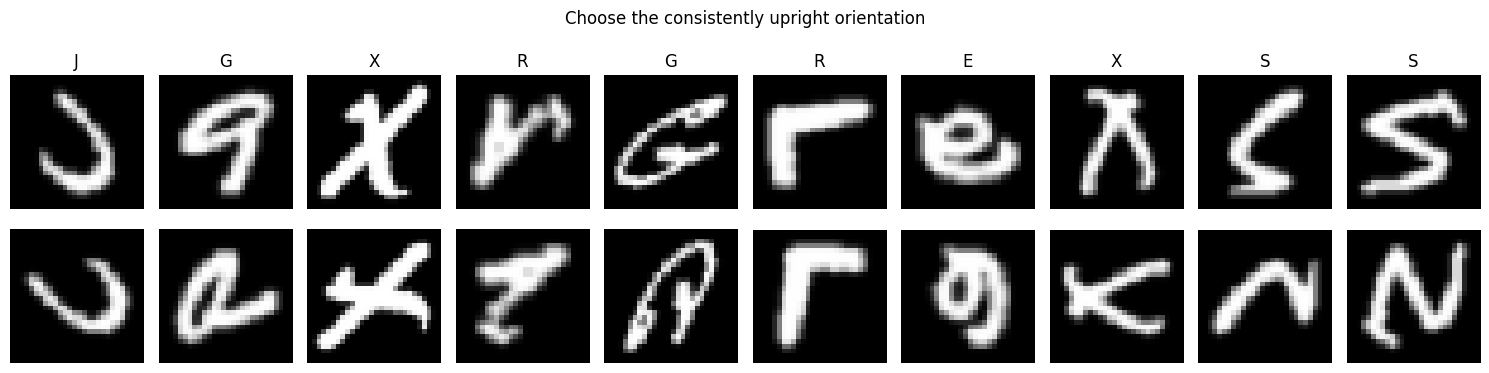

In [7]:
rng = np.random.default_rng(SEED)
choice = rng.choice(len(loaded), size=min(10, len(loaded)), replace=False)
fig, axes = plt.subplots(2, len(choice), figsize=(15, 4))
for i, idx in enumerate(choice):
    rec = loaded[int(idx)]
    axes[0, i].imshow(rec["pixels"], cmap="gray", vmin=0, vmax=255)
    axes[1, i].imshow(rec["pixels"].T, cmap="gray", vmin=0, vmax=255)
    for ax in (axes[0, i], axes[1, i]):
        ax.axis("off")
    axes[0, i].set_title(CLASS_NAMES[rec["label"]])
axes[0, 0].set_ylabel("Original", fontsize=11)
axes[1, 0].set_ylabel("Transposed", fontsize=11)
plt.suptitle("Choose the consistently upright orientation")
plt.tight_layout()
plt.show()

In [8]:
# IMPORTANT: make a conscious choice after viewing the grid above.
TRANSPOSE_SOURCE_IMAGES = False  # Change to True ONLY if the second row is upright.

print("Transpose the source PNGs?", TRANSPOSE_SOURCE_IMAGES)

Transpose the source PNGs? False


## Step 6 — remove exact duplicate images and check for conflicting labels

An exact duplicate could otherwise appear in training and test, making the test easier than it should be. We fingerprint the grayscale pixel arrays with SHA-256, retain one copy and flag if the same picture has different labels. This does **not** detect near-duplicates or multiple samples from the same writer. Without writer IDs, writer-independent evaluation cannot be guaranteed.

In [9]:
unique = []
seen = {}
exact_duplicates = 0
conflicts = []

for rec in loaded:
    pixels = rec["pixels"].T.copy() if TRANSPOSE_SOURCE_IMAGES else rec["pixels"].copy()
    digest = hashlib.sha256(pixels.tobytes()).hexdigest()
    if digest in seen:
        previous = seen[digest]
        if previous["label"] != rec["label"]:
            conflicts.append((previous["id"], rec["id"], previous["raw_label"], rec["raw_label"]))
        else:
            exact_duplicates += 1
        continue
    item = {**rec, "pixels": pixels, "sha256": digest}
    seen[digest] = item
    unique.append(item)

if conflicts:
    raise ValueError(f"Same image assigned different labels; investigate before training: {conflicts[:5]}")

print("Removed exact duplicates:", exact_duplicates)
print("Unique images remaining:", len(unique))
X_uint8 = np.stack([r["pixels"] for r in unique]).astype(np.uint8)
y_all = np.array([r["label"] for r in unique], dtype=np.int64)
assert X_uint8.shape[1:] == (28, 28)
assert set(np.unique(y_all)) == set(range(26))

Removed exact duplicates: 0
Unique images remaining: 10000


## Step 7 — fixed modeling splits, with original source test reserved

**Train:** fit model weights. **Validation:** select models and tune hyperparameters. **Test:** final held-out evaluation only, after model choices are finalized.

This dataset's source-tagged `test` subset lacks the letters T–Z. Therefore the code below takes only `train`-tagged images and creates a new **stratified 80% train / 10% validation / 10% test** partition *within those images*. It retains the original `test`-tagged 1,453 images separately as a secondary, partial-alphabet evaluation set. This is an explicit **new capstone split**, not the official EMNIST train/test benchmark. The same exported partitions must be used for all three models.


In [10]:
import numpy as np
from collections import Counter
from sklearn.model_selection import train_test_split

SEED = 42

# STEP 1: Identify original train and test images
def origin_split(tags):
    found = set(tags) & {"train", "test"}

    if len(found) > 1:
        return "ambiguous"

    return next(iter(found)) if found else "none"


origins = [origin_split(r["tags"]) for r in unique]

source_counts = Counter(origins)
print("Original tags found:", source_counts)

assert set(source_counts).issubset({"train", "test"}), (
    "Missing or ambiguous source tags. Inspect before splitting."
)

# STEP 2: Separate original training and testing images
source_train_idx = np.array([
    i for i, origin in enumerate(origins)
    if origin == "train"
])

source_test_idx = np.array([
    i for i, origin in enumerate(origins)
    if origin == "test"
])

# STEP 3: Create a new test set from original training data
train_val_idx, test_idx = train_test_split(
    source_train_idx,
    test_size=0.10,
    stratify=y_all[source_train_idx],
    random_state=SEED
)

# STEP 4: Create validation and training sets
train_idx, val_idx = train_test_split(
    train_val_idx,
    test_size=1/9,
    stratify=y_all[train_val_idx],
    random_state=SEED
)

# STEP 5: Store the final splits
split_idx = {
    "train": np.sort(train_idx),
    "val": np.sort(val_idx),
    "test": np.sort(test_idx)
}

source_policy = (
    "Stratified 80/10/10 split of original training data; "
    "original test data reserved separately"
)

# STEP 6: Check for data leakage and missing images
all_assigned = np.concatenate(list(split_idx.values()))

assert len(all_assigned) == len(set(all_assigned))
assert set(all_assigned) == set(source_train_idx)
assert set(all_assigned).isdisjoint(set(source_test_idx))

# STEP 7: Verify all 26 letters are present
print("\nFINAL DATASET SPLITS")
print("-" * 40)

for name, idx in split_idx.items():
    classes = set(y_all[idx].tolist())

    print(
        name,
        len(idx),
        "examples;",
        len(classes),
        "letter classes"
    )

    assert classes == set(range(26)), (
        f"{name} is missing some letters"
    )

print("-" * 40)
print("Reserved original test:", len(source_test_idx))
print("\nPreprocessing split completed successfully!")

Original tags found: Counter({'train': 8547, 'test': 1453})

FINAL DATASET SPLITS
----------------------------------------
train 6837 examples; 26 letter classes
val 855 examples; 26 letter classes
test 855 examples; 26 letter classes
----------------------------------------
Reserved original test: 1453

Preprocessing split completed successfully!


In [11]:
### QUICK CHECK BECAUSE THE CODE BEFORE THIS CELL FAILED:

for split_name in ["train", "test"]:
    idx = np.array([
        i for i, origin in enumerate(origins)
        if origin == split_name
    ])

    counts = Counter(y_all[idx].tolist())

    missing = [
        chr(65 + i)
        for i in range(26)
        if counts.get(i, 0) == 0
    ]

    print(f"\n{split_name.upper()} SET")
    print("Number of images:", len(idx))
    print("Missing letters:", missing)

    for i in range(26):
        print(chr(65 + i), counts.get(i, 0))


TRAIN SET
Number of images: 8547
Missing letters: []
A 318
B 332
C 342
D 332
E 316
F 340
G 298
H 331
I 330
J 342
K 327
L 339
M 312
N 302
O 338
P 322
Q 358
R 322
S 328
T 346
U 312
V 354
W 328
X 330
Y 331
Z 317

TEST SET
Number of images: 1453
Missing letters: ['T', 'U', 'V', 'W', 'X', 'Y', 'Z']
A 85
B 74
C 74
D 79
E 81
F 65
G 66
H 81
I 87
J 87
K 75
L 84
M 73
N 75
O 71
P 90
Q 79
R 82
S 45
T 0
U 0
V 0
W 0
X 0
Y 0
Z 0


## Step 8 — visually check label balance and image intensity

Inclusion on of a small EDA audit: counts per letter in each partition, unexpected missing/corrupted examples, duplicate count, and a sample gallery. No train-dependent statistics are fitted here; normalization in the next step is a fixed division by 255.

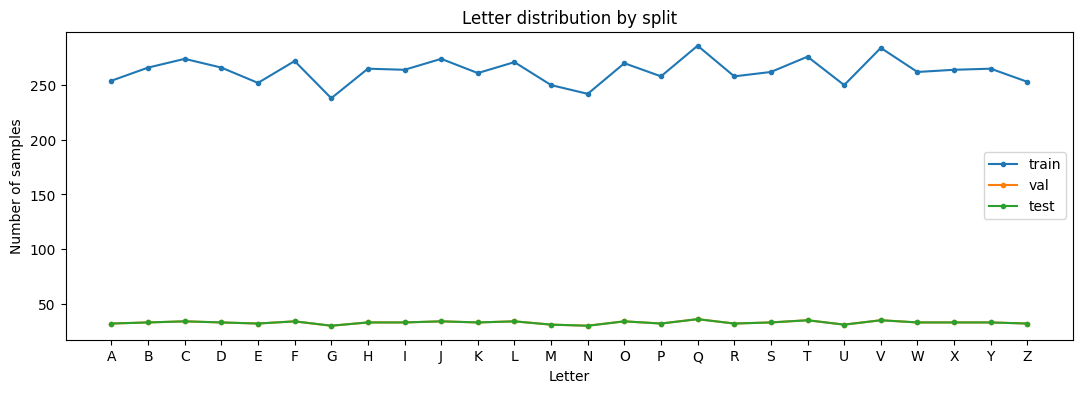

Source min/max pixel: 0 255
Mean pixel intensity: 44.12
Completely blank images (all zero): 0


In [12]:
fig, ax = plt.subplots(figsize=(13, 4))
for name in ("train", "val", "test"):
    class_counts = np.bincount(y_all[split_idx[name]], minlength=26)
    ax.plot(CLASS_NAMES, class_counts, marker=".", label=name)
ax.set(xlabel="Letter", ylabel="Number of samples", title="Letter distribution by split")
ax.legend()
plt.show()

print("Source min/max pixel:", int(X_uint8.min()), int(X_uint8.max()))
print("Mean pixel intensity:", round(float(X_uint8.mean()), 2))
print("Completely blank images (all zero):", int(np.sum(np.max(X_uint8, axis=(1, 2)) == 0)))

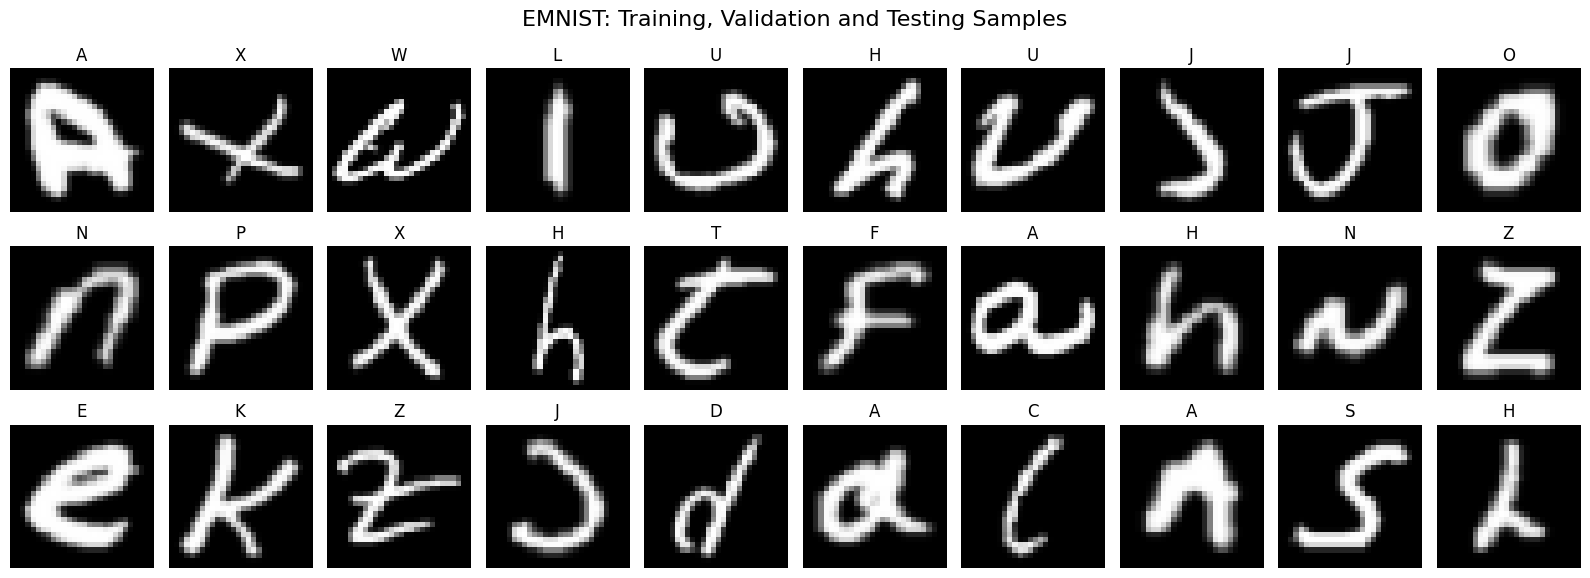

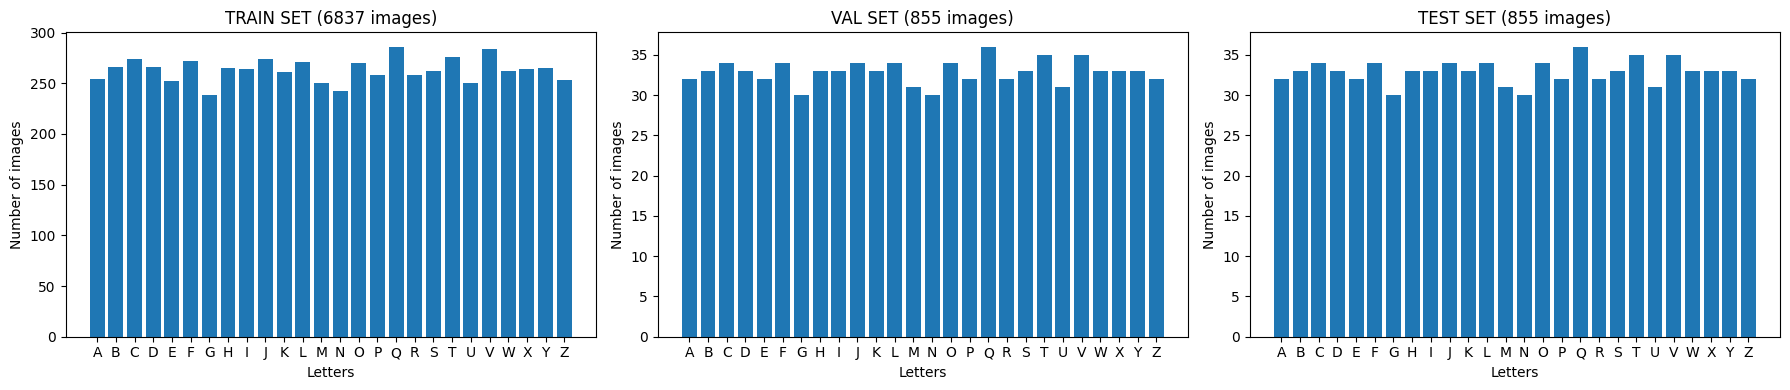

In [13]:
#### VISUALIZATION



import numpy as np
import matplotlib.pyplot as plt

# Show 10 random images from each dataset
fig, axes = plt.subplots(3, 10, figsize=(16, 6))

rng = np.random.default_rng(42)

for row, split_name in enumerate(["train", "val", "test"]):

    indices = split_idx[split_name]

    # Randomly select 10 images from the split
    selected = rng.choice(indices, size=10, replace=False)

    for col, idx in enumerate(selected):

        # Display the handwritten letter
        axes[row, col].imshow(
            X_uint8[idx],
            cmap="gray",
            vmin=0,
            vmax=255
        )

        # Display the correct letter label
        letter = CLASS_NAMES[int(y_all[idx])]
        axes[row, col].set_title(letter, fontsize=12)
        axes[row, col].axis("off")

    # Identify which dataset each row belongs to
    axes[row, 0].set_ylabel(
        split_name.upper(),
        fontsize=13,
        fontweight="bold"
    )

plt.suptitle(
    "EMNIST: Training, Validation and Testing Samples",
    fontsize=16
)

plt.tight_layout()
plt.show()


# Show class distribution across all three splits
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

for ax, split_name in zip(axes, ["train", "val", "test"]):

    labels = y_all[split_idx[split_name]]

    counts = np.bincount(labels, minlength=26)

    ax.bar(CLASS_NAMES, counts)

    ax.set_title(
        f"{split_name.upper()} SET ({len(labels)} images)"
    )
    ax.set_xlabel("Letters")
    ax.set_ylabel("Number of images")

plt.tight_layout()
plt.show()


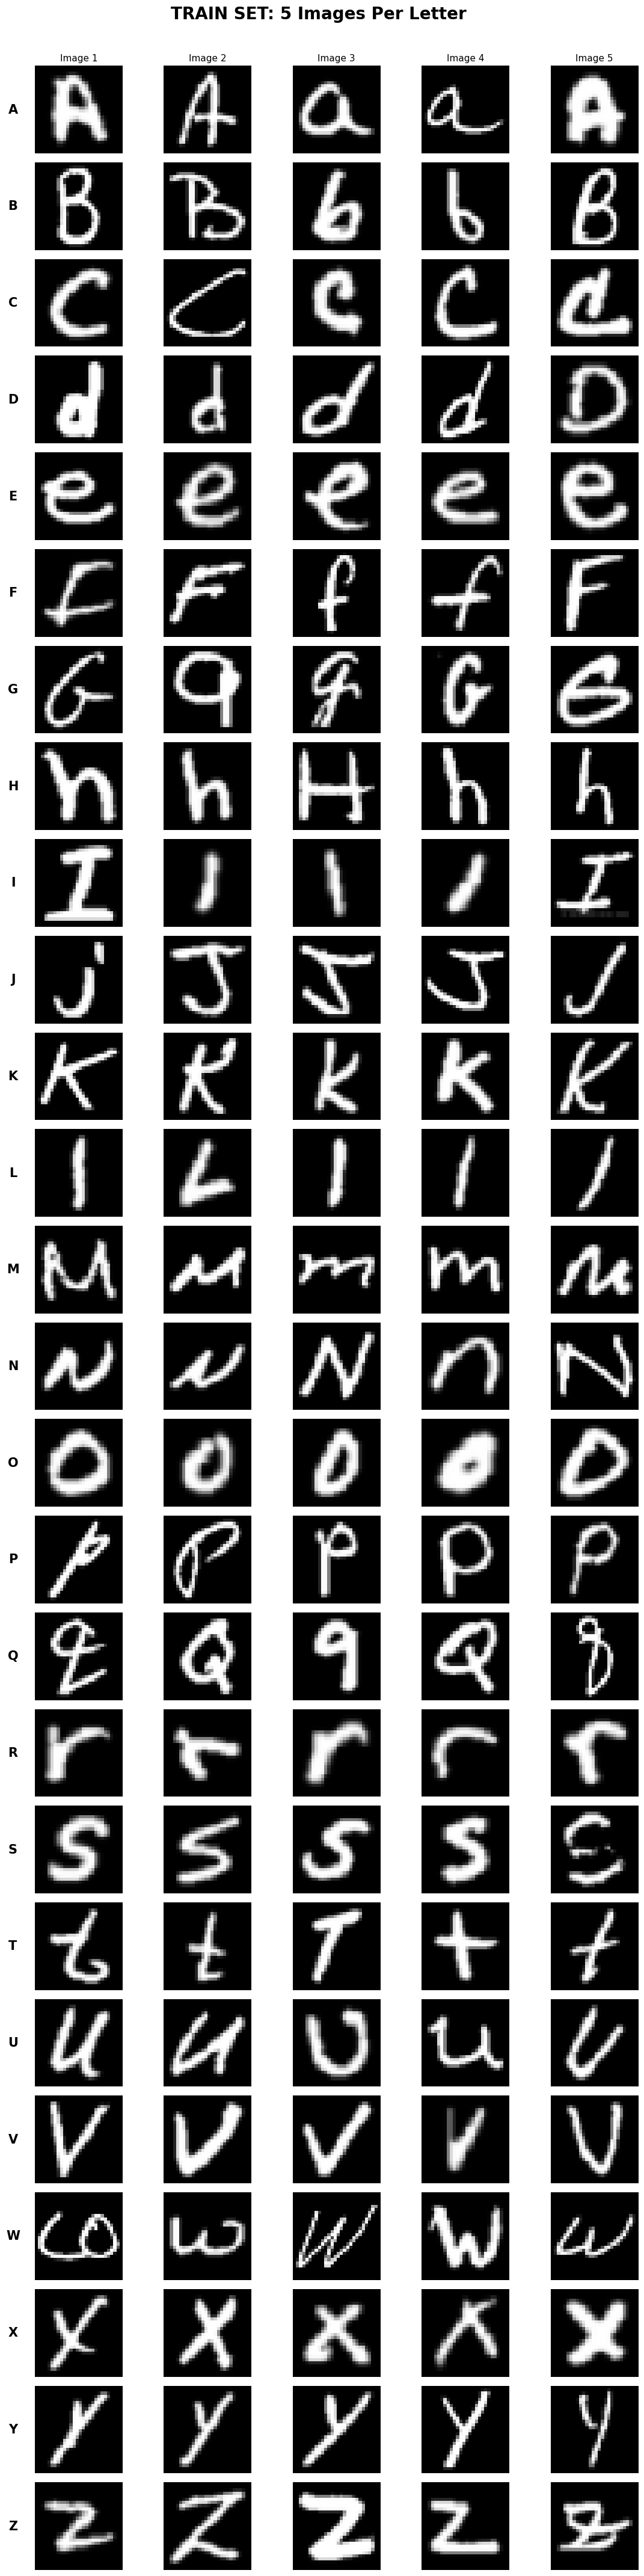

Completed TRAIN visualization


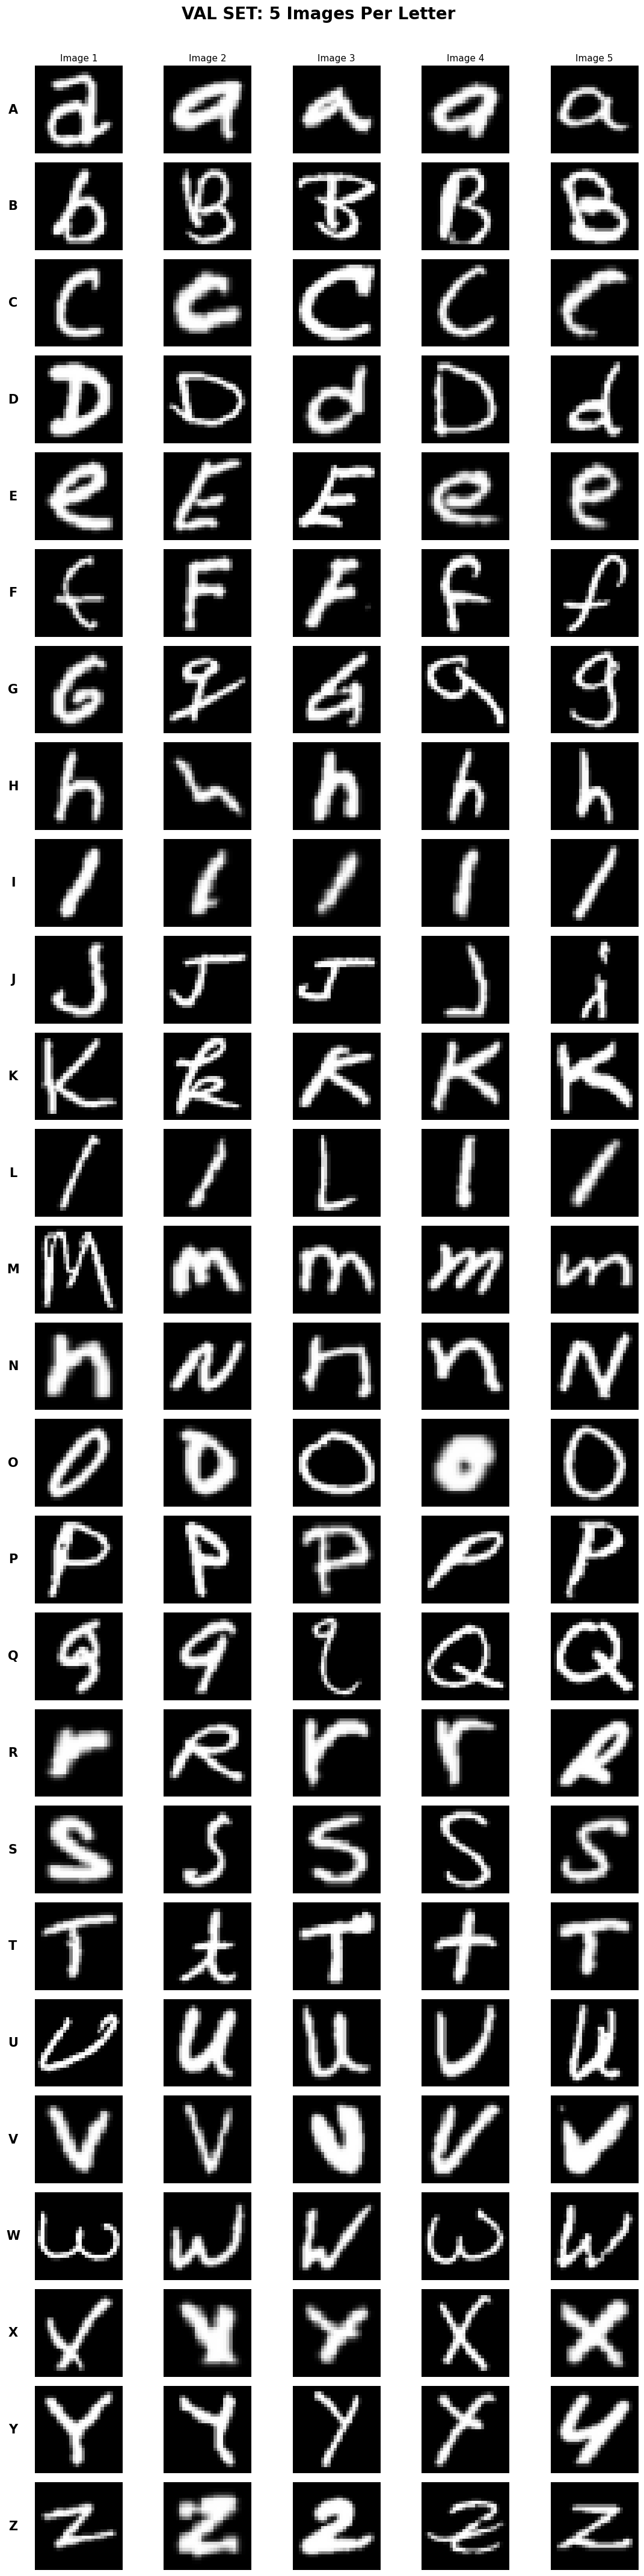

Completed VAL visualization


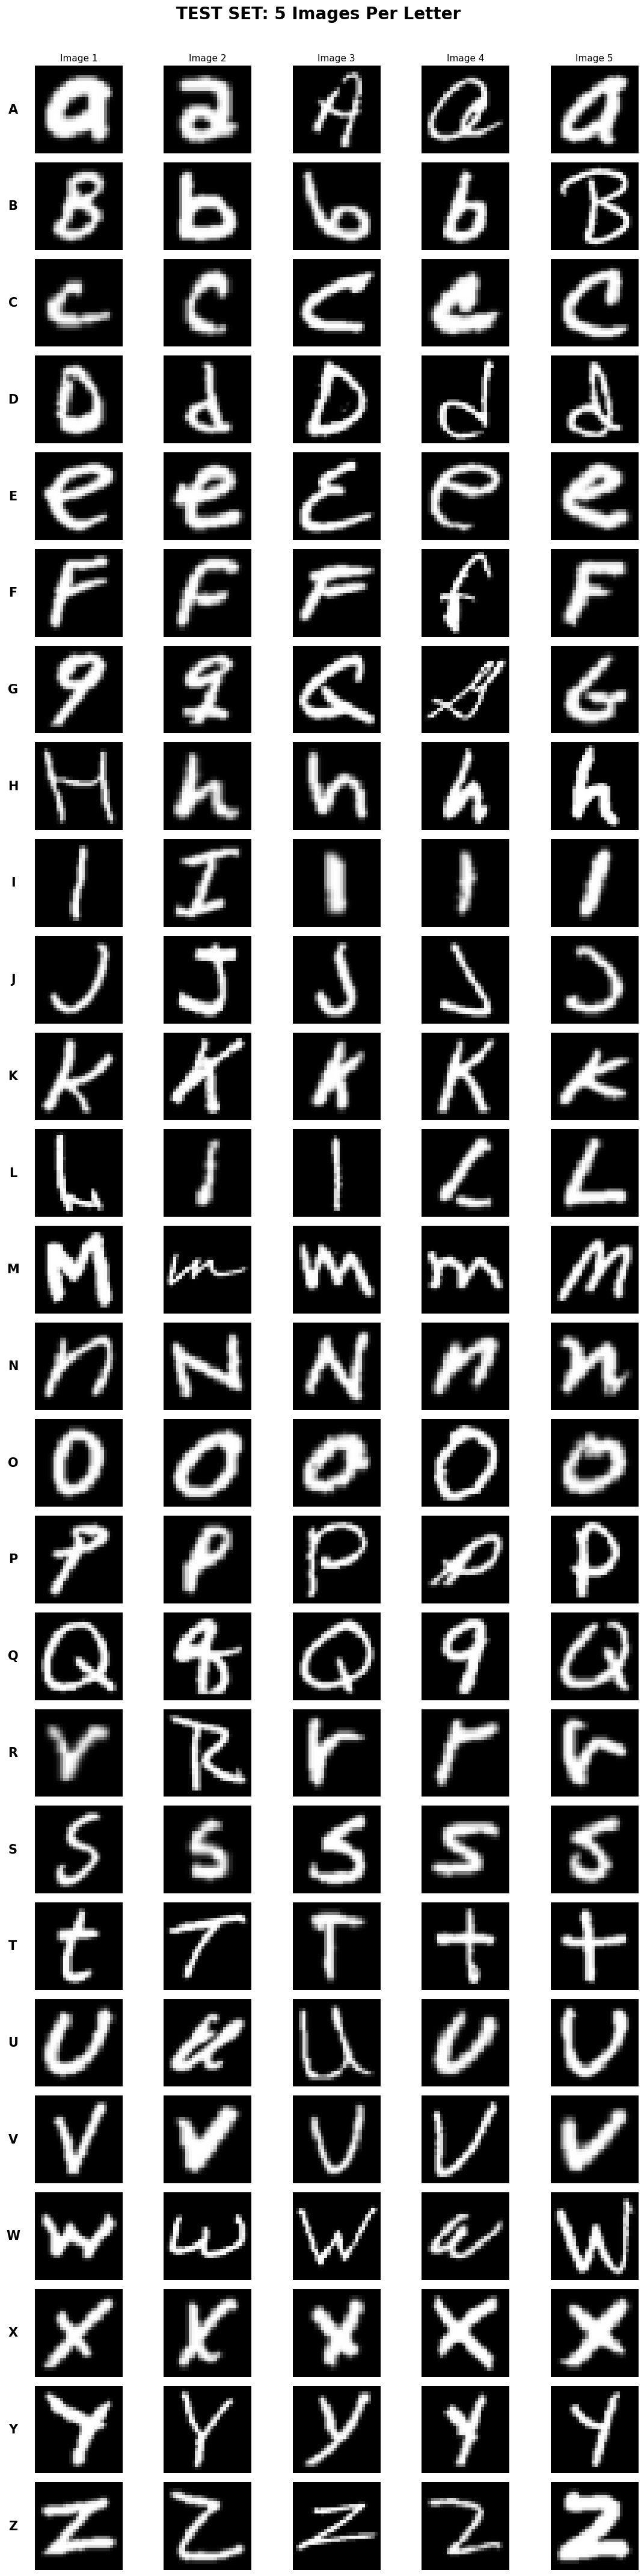

Completed TEST visualization


In [14]:
#### BETTER VISUALIZATION CHECK


import numpy as np
import matplotlib.pyplot as plt

SEED = 42
IMAGES_PER_LETTER = 5

rng = np.random.default_rng(SEED)

# Visualize all three dataset splits
for split_name in ["train", "val", "test"]:

    indices = split_idx[split_name]

    # 26 rows (A-Z), 5 images per row
    fig, axes = plt.subplots(
        26, IMAGES_PER_LETTER,
        figsize=(12, 43)
    )

    fig.suptitle(
        f"{split_name.upper()} SET: 5 Images Per Letter",
        fontsize=20,
        fontweight="bold",
        y=0.995
    )

    for letter_id in range(26):

        letter = chr(65 + letter_id)

        # Find all images belonging to this letter
        letter_indices = indices[
            y_all[indices] == letter_id
        ]

        # Randomly select 5 images
        sample_count = min(
            IMAGES_PER_LETTER,
            len(letter_indices)
        )

        selected = rng.choice(
            letter_indices,
            size=sample_count,
            replace=False
        )

        for col in range(IMAGES_PER_LETTER):

            ax = axes[letter_id, col]

            if col < sample_count:
                img_idx = selected[col]

                ax.imshow(
                    X_uint8[img_idx],
                    cmap="gray",
                    vmin=0,
                    vmax=255
                )

            ax.axis("off")

            # Column headings
            if letter_id == 0:
                ax.set_title(
                    f"Image {col + 1}",
                    fontsize=11
                )

        # Letter label at the beginning of each row
        axes[letter_id, 0].text(
            -0.25, 0.5,
            letter,
            transform=axes[letter_id, 0].transAxes,
            fontsize=15,
            fontweight="bold",
            ha="center",
            va="center"
        )

    plt.tight_layout(rect=[0.04, 0, 1, 0.99])
    plt.show()
    plt.close(fig)

    print(
        f"Completed {split_name.upper()} visualization"
    )



In [15]:
### MORE DATA QUALITY WORK


import numpy as np
from pathlib import Path
from itertools import combinations

OUTPUT_DIR = Path("emnist_preprocessed_v1")
OUTPUT_DIR.mkdir(exist_ok=True)

print("=" * 55)
print("EMNIST - FINAL DATA QUALITY AUDIT")
print("=" * 55)

# 1. Verify image dimensions and labels
assert X_uint8.shape[1:] == (28, 28)
assert X_uint8.dtype == np.uint8
assert set(np.unique(y_all)) == set(range(26))

print("\nImage shape:", X_uint8.shape)
print("Pixel type:", X_uint8.dtype)
print("Number of classes:", len(np.unique(y_all)))

# 2. Check each split for all 26 classes
for name in ["train", "val", "test"]:
    idx = split_idx[name]
    labels = y_all[idx]
    counts = np.bincount(labels, minlength=26)

    print(f"\n{name.upper()} SET")
    print("Images:", len(idx))
    print("Classes:", np.count_nonzero(counts))

    assert np.all(counts > 0), (
        f"Missing classes in {name}"
    )

# 3. Ensure no image indices overlap
for a, b in combinations(["train", "val", "test"], 2):
    overlap = np.intersect1d(split_idx[a], split_idx[b])

    print(f"\nIndex overlap {a}/{b}:", len(overlap))
    assert len(overlap) == 0

# 4. Check pixel-level quality
flat_images = X_uint8.reshape(len(X_uint8), -1)

blank_idx = np.where(
    flat_images.max(axis=1) == 0
)[0]

faint_idx = np.where(
    (flat_images.max(axis=1) > 0) &
    (flat_images.max(axis=1) < 64)
)[0]

foreground_count = (X_uint8 > 20).sum(axis=(1, 2))

low_foreground_idx = np.where(
    foreground_count < 5
)[0]

print("\nIMAGE QUALITY RESULTS")
print("Completely blank images:", len(blank_idx))
print("Potentially faint images:", len(faint_idx))
print("Images with fewer than 5 foreground pixels:",
      len(low_foreground_idx))

print("\nPotentially faint image indices:",
      faint_idx[:20].tolist())

print("Low-foreground image indices:",
      low_foreground_idx[:20].tolist())

# 5. Save qualitative observations
quality_notes = f"""
EMNIST HANDWRITTEN LETTERS - DATA QUALITY REPORT

DATASET
Voxel51/emnist-letters-tiny

TOTAL UNIQUE IMAGES
{len(X_uint8)}

MAIN MODELING SPLITS
Training: {len(split_idx['train'])}
Validation: {len(split_idx['val'])}
Testing: {len(split_idx['test'])}

ORIGINAL SOURCE TEST (RESERVED)
{len(source_test_idx)} images

CHARACTER AMBIGUITY OBSERVATIONS
- U, V and Y have visually similar handwritten forms.
- Some R characters resemble V.
- Some G characters resemble Q or the digit 9.
- Some L characters resemble I or the digit 1.
- Some Q characters resemble P.
- Some C characters resemble O.
- J exhibits substantial handwriting variation.
- Z exhibits stroke thickness and intensity variation.

IMPORTANT
These are observations from visual inspection.
They are not confirmed labeling errors.

IMAGE QUALITY FLAGS
Completely blank images: {len(blank_idx)}
Potentially faint images: {len(faint_idx)}
Images with very little foreground: {len(low_foreground_idx)}

PREPROCESSING DECISIONS
- Retain potentially valid ambiguous handwriting.
- Preserve grayscale images.
- Do not automatically relabel ambiguous samples.
- Do not perform aggressive brightness correction.
- Check for corrupted images and duplicate content.
- Use fixed stratified train/validation/test splits.
- Reserve original source test samples separately.

LIMITATIONS
- Original source test subset is missing T through Z.
- Some characters may be visually ambiguous.
- Writer-independent splitting was not established.
- Image-quality thresholds are review flags, not
  automatic criteria for removing samples.
"""

report_path = OUTPUT_DIR / "quality_findings.txt"
report_path.write_text(
    quality_notes.strip(), encoding="utf-8"
)

print("\nQuality report saved:", report_path)

if len(blank_idx) > 0:
    raise ValueError(
        "Blank images found. Inspect them before exporting."
    )

print("\nFinal data quality checks completed!")





EMNIST - FINAL DATA QUALITY AUDIT

Image shape: (10000, 28, 28)
Pixel type: uint8
Number of classes: 26

TRAIN SET
Images: 6837
Classes: 26

VAL SET
Images: 855
Classes: 26

TEST SET
Images: 855
Classes: 26

Index overlap train/val: 0

Index overlap train/test: 0

Index overlap val/test: 0

IMAGE QUALITY RESULTS
Completely blank images: 0
Potentially faint images: 0
Images with fewer than 5 foreground pixels: 0

Potentially faint image indices: []
Low-foreground image indices: []

Quality report saved: emnist_preprocessed_v1/quality_findings.txt

Final data quality checks completed!


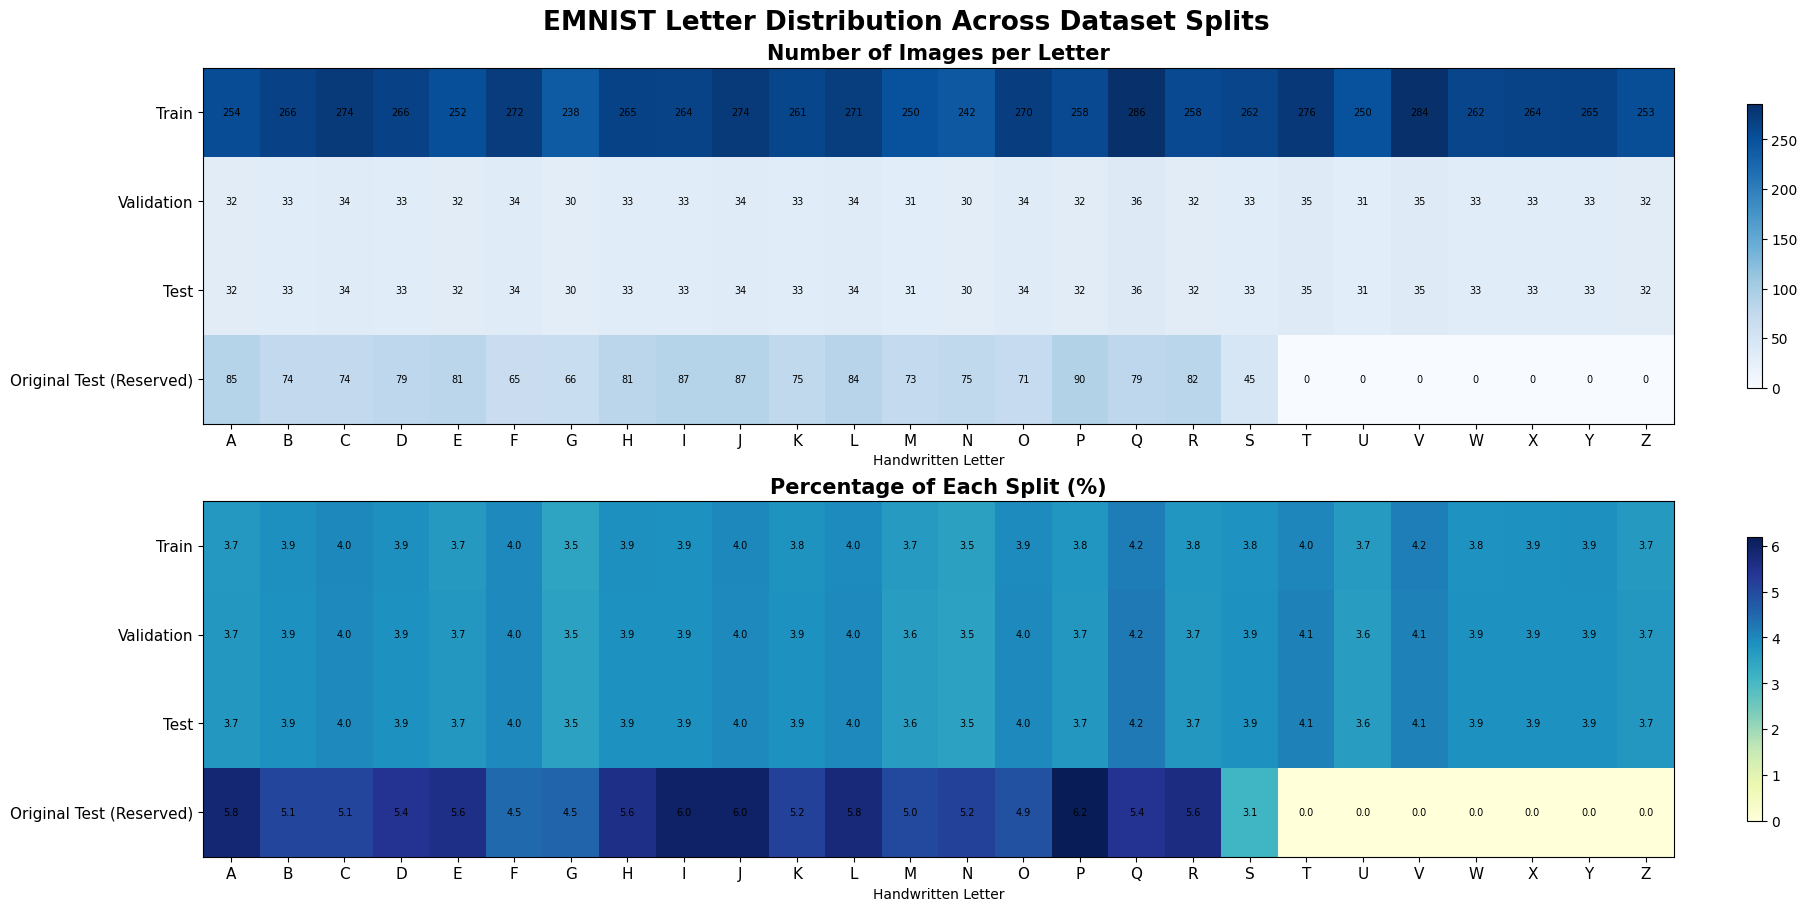

In [16]:
### Visualization 1: Distribution heatmaps


import numpy as np
import matplotlib.pyplot as plt

# Main model splits
names = ["Train", "Validation", "Test"]

indices = [
    split_idx["train"],
    split_idx["val"],
    split_idx["test"]
]

# Include original source test for comparison
names.append("Original Test (Reserved)")
indices.append(source_test_idx)

# Count every letter in each split
counts = np.array([
    np.bincount(y_all[idx], minlength=26)
    for idx in indices
])

# Convert counts into percentages
percentages = (
    counts / counts.sum(axis=1, keepdims=True)
) * 100

fig, axes = plt.subplots(
    2, 1,
    figsize=(18, 9),
    constrained_layout=True
)

charts = [
    (counts, "Number of Images per Letter", "Blues"),
    (percentages, "Percentage of Each Split (%)", "YlGnBu")
]

for ax, (data, title, cmap) in zip(axes, charts):

    im = ax.imshow(
        data,
        cmap=cmap,
        aspect="auto"
    )

    ax.set_xticks(range(26))
    ax.set_xticklabels(CLASS_NAMES, fontsize=11)

    ax.set_yticks(range(len(names)))
    ax.set_yticklabels(names, fontsize=11)

    ax.set_xlabel("Handwritten Letter")
    ax.set_title(title, fontsize=15, fontweight="bold")

    # Display actual numbers inside each cell
    for row in range(data.shape[0]):
        for col in range(data.shape[1]):

            value = data[row, col]

            label = (
                f"{int(value)}"
                if title.startswith("Number")
                else f"{value:.1f}"
            )

            ax.text(
                col, row, label,
                ha="center",
                va="center",
                fontsize=7,
                color="black"
            )

    fig.colorbar(im, ax=ax, shrink=0.8)

fig.suptitle(
    "EMNIST Letter Distribution Across Dataset Splits",
    fontsize=19,
    fontweight="bold"
)

fig.savefig(
    OUTPUT_DIR / "class_distribution_heatmaps.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


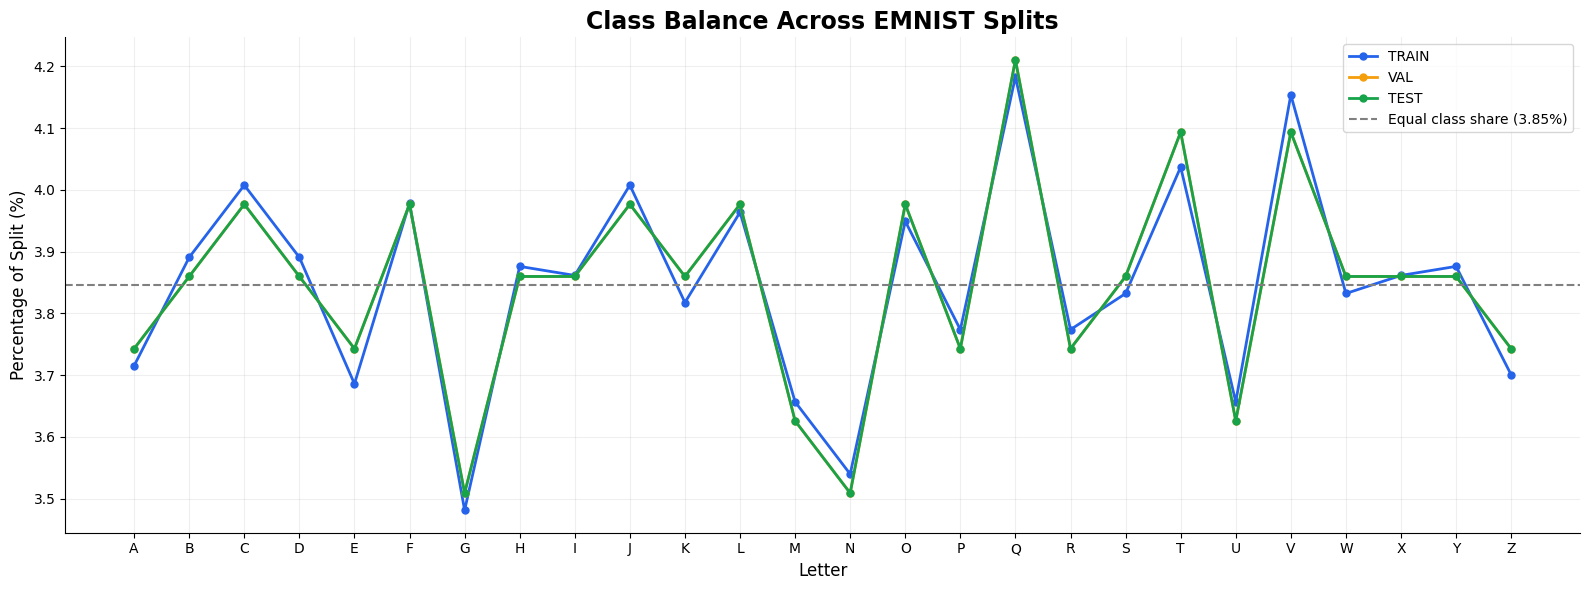

In [17]:
### Visualization 2: Normalized class-distribution comparison



import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(16, 6))

colors = ["#2563EB", "#F59E0B", "#16A34A"]

for name, color in zip(
    ["train", "val", "test"], colors
):

    labels = y_all[split_idx[name]]

    counts = np.bincount(
        labels, minlength=26
    )

    percentages = 100 * counts / counts.sum()

    ax.plot(
        CLASS_NAMES,
        percentages,
        marker="o",
        linewidth=2,
        markersize=5,
        label=name.upper(),
        color=color
    )

# Ideal reference for 26 equally represented letters
ax.axhline(
    100 / 26,
    color="gray",
    linestyle="--",
    linewidth=1.5,
    label="Equal class share (3.85%)"
)

ax.set_title(
    "Class Balance Across EMNIST Splits",
    fontsize=17,
    fontweight="bold"
)

ax.set_xlabel("Letter", fontsize=12)
ax.set_ylabel("Percentage of Split (%)", fontsize=12)

ax.grid(alpha=0.2)
ax.legend()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "class_balance_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


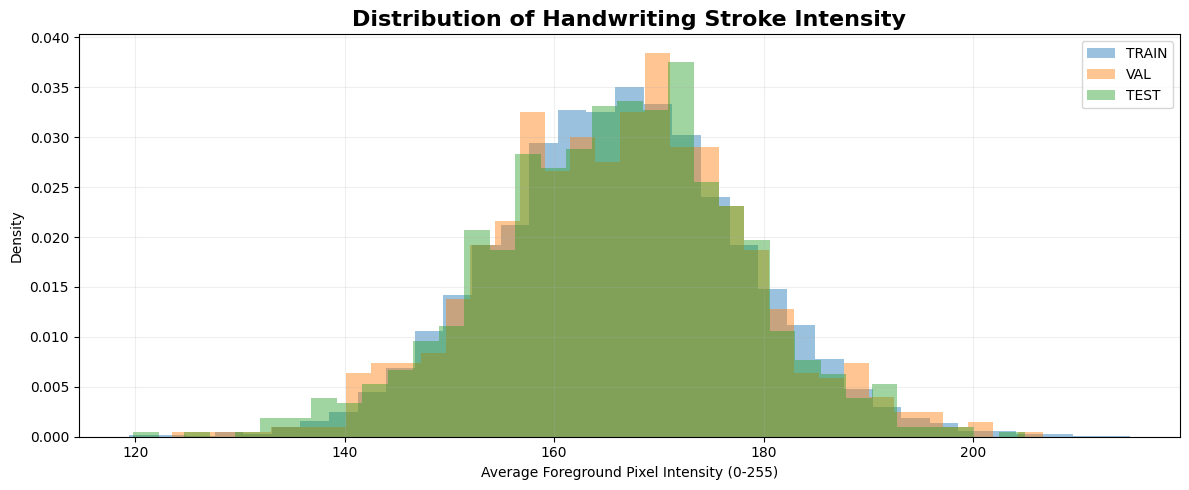

In [18]:
### Pixel intensity


import numpy as np
import matplotlib.pyplot as plt

# Consider pixels above 20 as foreground for analysis
foreground_mask = X_uint8 > 20

foreground_pixels = foreground_mask.sum(axis=(1, 2))

stroke_sum = (
    X_uint8.astype(np.float32) * foreground_mask
).sum(axis=(1, 2))

mean_stroke_intensity = stroke_sum / np.maximum(
    foreground_pixels, 1
)

fig, ax = plt.subplots(figsize=(12, 5))

for name in ["train", "val", "test"]:
    idx = split_idx[name]

    ax.hist(
        mean_stroke_intensity[idx],
        bins=35,
        density=True,
        alpha=0.45,
        label=name.upper()
    )

ax.set_title(
    "Distribution of Handwriting Stroke Intensity",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel("Average Foreground Pixel Intensity (0-255)")
ax.set_ylabel("Density")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "stroke_intensity_distribution.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


## Step 9 — normalize pixel values and export shared files

In a grayscale 8-bit image, pixel values range from **0 to 255**. `pixels / 255.0` changes them to **0.0–1.0**, which is easier for neural networks to train on. It does **not** remove any classes or change the letter label.

We save images as `(N, 28, 28, 1)` — the final **1** is one grayscale channel. CNN teammates use that shape directly. ANN/MLP teammates flatten each 28×28 picture to **784 numbers** *inside their own model code*. Keeping a canonical unflattened dataset prevents divergence.

Outputs include exact split assignment manifest, preprocessing configuration, class balance report, and `.npz` arrays.

In [19]:

# STEP 9: NORMALIZE AND EXPORT THE SHARED DATASET

import numpy as np
import pandas as pd
import csv
import json
from pathlib import Path

OUTPUT_DIR = Path("emnist_preprocessed_v1")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

export_rows = []

# --------------------------------------------------
# 1. Export train, validation and test datasets
# --------------------------------------------------

for name, idx in split_idx.items():

    # Convert pixel values from 0-255 to 0-1
    images = X_uint8[idx].astype(np.float32) / 255.0

    # Add channel dimension: (N, 28, 28, 1)
    images = images[..., np.newaxis]

    labels = y_all[idx]

    sample_ids = np.array(
        [unique[int(i)]["id"] for i in idx],
        dtype=str
    )

    # Validate images
    assert images.dtype == np.float32
    assert images.shape[1:] == (28, 28, 1)
    assert 0 <= images.min() and images.max() <= 1
    assert set(np.unique(labels)) == set(range(26))

    # Save files
    np.savez_compressed(
        OUTPUT_DIR / f"{name}.npz",
        X=images,
        y=labels,
        sample_id=sample_ids
    )

    # Build manifest
    for i in idx:
        r = unique[int(i)]

        export_rows.append({
            "source_sample_id": r["id"],
            "source_tags": ";".join(r["tags"]),
            "split": name,
            "label_id": int(y_all[i]),
            "letter": CLASS_NAMES[int(y_all[i])],
            "sha256": r["sha256"]
        })

    print(
        f"Saved {name}.npz: "
        f"X={images.shape}, y={labels.shape}"
    )


# --------------------------------------------------
# 2. Preserve original source test separately
# --------------------------------------------------

reserved_idx = np.sort(source_test_idx)

reserved_images = (
    X_uint8[reserved_idx].astype(np.float32) / 255.0
)

reserved_images = reserved_images[..., np.newaxis]

reserved_labels = y_all[reserved_idx]

reserved_ids = np.array(
    [unique[int(i)]["id"] for i in reserved_idx],
    dtype=str
)

np.savez_compressed(
    OUTPUT_DIR / "original_test_optional.npz",
    X=reserved_images,
    y=reserved_labels,
    sample_id=reserved_ids
)

for i in reserved_idx:
    r = unique[int(i)]

    export_rows.append({
        "source_sample_id": r["id"],
        "source_tags": ";".join(r["tags"]),
        "split": "original_test_optional",
        "label_id": int(y_all[i]),
        "letter": CLASS_NAMES[int(y_all[i])],
        "sha256": r["sha256"]
    })

print(
    f"Saved original_test_optional.npz: "
    f"X={reserved_images.shape}"
)

# Verify all original unique records are accounted for
assert len(export_rows) == len(unique)
assert len({r["source_sample_id"] for r in export_rows}) == len(unique)


# --------------------------------------------------
# 3. Save dataset manifest
# --------------------------------------------------

with (OUTPUT_DIR / "manifest.csv").open(
    "w", newline="", encoding="utf-8"
) as f:

    writer = csv.DictWriter(
        f,
        fieldnames=list(export_rows[0].keys())
    )

    writer.writeheader()
    writer.writerows(export_rows)

print("Saved manifest.csv")


# --------------------------------------------------
# 4. Save class distribution information
# --------------------------------------------------

all_splits = {
    **split_idx,
    "original_test_optional": reserved_idx
}

with (OUTPUT_DIR / "class_distribution.csv").open(
    "w", newline="", encoding="utf-8"
) as f:

    writer = csv.writer(f)

    writer.writerow([
        "split", "label_id", "letter", "count"
    ])

    for name, idx in all_splits.items():

        counts = np.bincount(
            y_all[idx],
            minlength=26
        )

        for class_id, count in enumerate(counts):

            writer.writerow([
                name,
                class_id,
                CLASS_NAMES[class_id],
                int(count)
            ])

print("Saved class_distribution.csv")


# --------------------------------------------------
# 5. Save preprocessing configuration
# --------------------------------------------------

config = {
    "dataset_source": DATASET_ID,
    "random_seed": SEED,
    "split_policy": source_policy,
    "source_tag_counts": dict(source_counts),

    "class_names": list(CLASS_NAMES),
    "label_mapping": {
        c: i for i, c in enumerate(CLASS_NAMES)
    },

    "source_label_scheme": label_scheme,

    "n_source": len(source),
    "n_loaded": len(loaded),
    "n_rejected": len(rejected),

    "n_removed_exact_duplicates": exact_duplicates,

    "n_unique_after_deduplication": len(unique),

    # Main modeling dataset only
    "n_final": sum(
        len(idx) for idx in split_idx.values()
    ),

    "n_reserved_original_test": len(reserved_idx),

    "split_sizes": {
        name: len(idx)
        for name, idx in all_splits.items()
    },

    "image_shape": [28, 28, 1],
    "dtype": "float32",
    "pixel_range": [0, 1],

    "preprocessing": [
        "Convert to grayscale",
        "Verify image orientation",
        "Remove exact duplicates",
        "Stratified data splitting",
        "Normalize pixels by dividing by 255"
    ],

    "transpose_source_images": TRANSPOSE_SOURCE_IMAGES,

    "augmentation": "Not performed",

    "ambiguous_handwriting_policy": (
        "Retain potentially valid ambiguous handwriting"
    ),

    "original_test_policy": (
        "Reserved separately because T-Z are absent"
    ),

    "external_handwriting": (
        "Not included in the modeling dataset"
    )
}

with (OUTPUT_DIR / "preprocessing_config.json").open(
    "w", encoding="utf-8"
) as f:

    json.dump(config, f, indent=2)

print("Saved preprocessing_config.json")


# --------------------------------------------------
# 6. Save rejected records if available
# --------------------------------------------------

if rejected:

    with (OUTPUT_DIR / "rejected_records.json").open(
        "w", encoding="utf-8"
    ) as f:

        json.dump(rejected, f, indent=2)


# --------------------------------------------------
# 7. Final export summary
# --------------------------------------------------

print("\n" + "=" * 55)
print("EMNIST PREPROCESSING EXPORT COMPLETE")
print("=" * 55)

for name, idx in all_splits.items():

    print(
        f"{name:25s}: {len(idx):5d} images "
        f"| {len(np.unique(y_all[idx]))} classes"
    )

print("\nMain modeling images:", config["n_final"])
print("Reserved original test:", len(reserved_idx))
print("Total unique images:", len(unique))

print("\nAll files saved to:")
print(OUTPUT_DIR.resolve())


Saved train.npz: X=(6837, 28, 28, 1), y=(6837,)
Saved val.npz: X=(855, 28, 28, 1), y=(855,)
Saved test.npz: X=(855, 28, 28, 1), y=(855,)
Saved original_test_optional.npz: X=(1453, 28, 28, 1)
Saved manifest.csv
Saved class_distribution.csv
Saved preprocessing_config.json

EMNIST PREPROCESSING EXPORT COMPLETE
train                    :  6837 images | 26 classes
val                      :   855 images | 26 classes
test                     :   855 images | 26 classes
original_test_optional   :  1453 images | 19 classes

Main modeling images: 8547
Reserved original test: 1453
Total unique images: 10000

All files saved to:
/content/emnist_preprocessed_v1


In [24]:

# STEP 9B: EXPORT REAL PNG IMAGES
# Uses the SAME cleaned images and fixed splits

from pathlib import Path
from PIL import Image
import numpy as np

PNG_DIR = Path("emnist_preprocessed_v1/images_png")

total_saved = 0

for split_name in ["train", "val", "test"]:

    indices = split_idx[split_name]

    for idx in indices:

        # Get correct letter
        label_id = int(y_all[idx])
        letter = CLASS_NAMES[label_id]

        # Create letter folder
        letter_folder = PNG_DIR / split_name / letter
        letter_folder.mkdir(
            parents=True,
            exist_ok=True
        )

        # Get the already cleaned image
        image = X_uint8[idx]

        # Save actual grayscale PNG
        filename = f"{letter}_{int(idx):06d}.png"

        Image.fromarray(
            image.astype(np.uint8),
            mode="L"
        ).save(letter_folder / filename)

        total_saved += 1

    print(
        f"{split_name.upper()}: "
        f"{len(indices)} PNG images saved"
    )

print("\nTotal PNG images saved:", total_saved)
print("Folder:", PNG_DIR.resolve())

assert total_saved == sum(
    len(split_idx[s])
    for s in ["train", "val", "test"]
)

print("PNG export completed successfully!")


/tmp/ipykernel_1425/3113160701.py:35: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(


TRAIN: 6837 PNG images saved
VAL: 855 PNG images saved
TEST: 855 PNG images saved

Total PNG images saved: 8547
Folder: /content/emnist_preprocessed_v1/images_png
PNG export completed successfully!


## Step 10 — reopen and inspect a saved training image

This sample comes from `train.npz`, not from the in-memory arrays. It is a quick human-readable check that saving/reloading preserves the image.

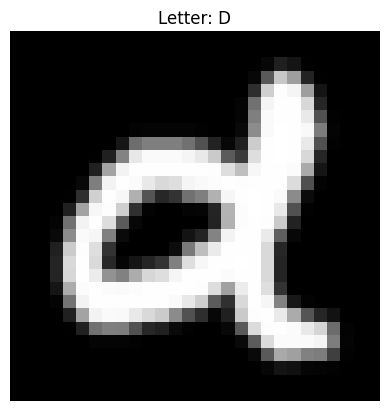

In [20]:
import numpy as np
import matplotlib.pyplot as plt

data = np.load("emnist_preprocessed_v1/train.npz")

X = data["X"]
y = data["y"]

plt.imshow(X[0].squeeze(), cmap="gray")
plt.title(f"Letter: {chr(65 + int(y[0]))}")
plt.axis("off")
plt.show()

## Step 11 — verify **all exported files** before sharing

This independent read-back verification checks the exact shapes and pixel ranges of every `.npz`, label IDs, matching CSV metadata, disjoint source IDs and image hashes between splits, and complete class coverage in the three main splits. It does **not** prove every manually ambiguous character label is correct.


In [21]:
# STEP 11: Verify the SAVED files, not just the original notebook variables.
from pathlib import Path
from collections import Counter
import csv
import json
import numpy as np

output_dir = Path("emnist_preprocessed_v1")
main_names = ["train", "val", "test"]
all_names = main_names + ["original_test_optional"]

with (output_dir / "manifest.csv").open(encoding="utf-8", newline="") as f:
    manifest = list(csv.DictReader(f))
with (output_dir / "preprocessing_config.json").open(encoding="utf-8") as f:
    config_saved = json.load(f)
with (output_dir / "class_distribution.csv").open(encoding="utf-8", newline="") as f:
    distribution_rows = list(csv.DictReader(f))

assert len(manifest) == 10000, "Expected 10,000 unique source records for this run"
assert len({r["source_sample_id"] for r in manifest}) == len(manifest)
assert len({r["sha256"] for r in manifest}) == len(manifest), "Duplicate pixel contents remain"

seen_ids, seen_hashes = set(), set()
expected_shape = (28, 28, 1)
for name in all_names:
    records = [r for r in manifest if r["split"] == name]
    by_id = {r["source_sample_id"]: r for r in records}
    assert len(by_id) == len(records), f"Duplicate sample IDs in {name}"

    with np.load(output_dir / f"{name}.npz", allow_pickle=False) as saved:
        assert {"X", "y", "sample_id"}.issubset(saved.files)
        X = saved["X"]
        y = saved["y"]
        ids = saved["sample_id"].astype(str)

    assert X.ndim == 4 and X.shape[1:] == expected_shape, f"Unexpected image shape: {name}"
    assert X.dtype == np.float32, f"Expected float32: {name}"
    assert np.all(np.isfinite(X)), f"Non-finite pixels: {name}"
    assert X.min() >= 0.0 and X.max() <= 1.0, f"Pixels out of range: {name}"
    assert len(X) == len(y) == len(ids) == len(records), f"Different lengths: {name}"
    assert set(ids) == set(by_id), f"CSV/NPZ sample IDs do not match: {name}"
    assert all(0 <= int(label) <= 25 for label in y), f"Invalid labels: {name}"
    assert all(int(by_id[sid]["label_id"]) == int(label) for sid, label in zip(ids,y)), f"CSV/NPZ labels disagree: {name}"

    ids_set = set(ids)
    hashes_set = {r["sha256"] for r in records}
    assert not (ids_set & seen_ids), f"Sample overlap involving {name}"
    assert not (hashes_set & seen_hashes), f"Image-content overlap involving {name}"
    seen_ids.update(ids_set)
    seen_hashes.update(hashes_set)

    counts = np.bincount(y.astype(np.int64), minlength=26)
    if name in main_names:
        assert np.all(counts > 0), f"Missing letters in main split {name}"
    expected_counts = {int(r["label_id"]): int(r["count"]) for r in distribution_rows if r["split"] == name}
    assert len(expected_counts) == 26
    assert all(expected_counts[k] == int(counts[k]) for k in range(26)), f"Class count mismatch: {name}"
    assert len(X) == config_saved["split_sizes"][name], f"Config size mismatch: {name}"
    print(f"PASS {name:24s}  images={len(X):5d}  classes={len(np.unique(y)):2d}  range=[{X.min():.2f}, {X.max():.2f}]")

assert len(seen_ids) == len(manifest)
assert sum(config_saved["split_sizes"][name] for name in main_names) == config_saved["n_final"]
print("\nALL EXPORTED FILES VERIFIED. The model splits are ready to be packaged.")


PASS train                     images= 6837  classes=26  range=[0.00, 1.00]
PASS val                       images=  855  classes=26  range=[0.00, 1.00]
PASS test                      images=  855  classes=26  range=[0.00, 1.00]
PASS original_test_optional    images= 1453  classes=19  range=[0.00, 1.00]

ALL EXPORTED FILES VERIFIED. The model splits are ready to be packaged.


## Step 12 — create a team README and downloadable ZIP

Only run this **after Step 11 prints `ALL EXPORTED FILES VERIFIED`**. The ZIP includes `.npz` image arrays, manifests, configuration, your data-quality notes, and the EDA plots saved to `emnist_preprocessed_v1`. Also share this `.ipynb` notebook in Drive separately so your team can reproduce the work.


In [22]:
# STEP 12: Document how teammates load the exact exported splits and package everything.
from pathlib import Path
from IPython.display import FileLink, display
import shutil
import zipfile

output_dir = Path("emnist_preprocessed_v1")
readme = """EMNIST CAPSTONE - SHARED DATASET v1

Source: Voxel51/emnist-letters-tiny, 10,000 images in this download.
Task: 26-class A-Z classification. Upper/lowercase are combined per letter.

MAIN SPLITS (same images for ANN and both CNNs):
  train.npz   6,837 images, 26 classes
  val.npz       855 images, 26 classes
  test.npz      855 images, 26 classes

SECONDARY SET:
  original_test_optional.npz   1,453 images, source-tagged test, A-S only.
  DO NOT use this as the primary 26-class evaluation or for training/tuning.

Each .npz contains:
  X          float32 array (N,28,28,1), pixel values in [0,1]
  y          integer labels 0=A, 1=B, ..., 25=Z
  sample_id  source sample identifiers

Teammates: load the SAME files; do not create new random splits.
ANN / MLP baseline: flatten X from (N,28,28,1) to (N,784) inside model code.
CNNs: use X directly as (N,28,28,1).
Keep val for hyperparameter selection; use test only for final model evaluation.
Train-only augmentation may be applied inside model training, never to val/test.

EXAMPLE:
  import numpy as np
  with np.load('train.npz', allow_pickle=False) as d:
      X_train, y_train = d['X'], d['y']

MANIFEST: manifest.csv maps sample IDs to labels, split name, source tags and image hashes.
CLASS COUNTS: class_distribution.csv contains counts per split per letter.
CONFIG: preprocessing_config.json records source, random seed and policy.
QUALITY: quality_findings.txt documents pixel checks and ambiguous writing.
EDA: PNG figures (if generated) contain class balance and intensity charts.

NOTES / LIMITATIONS:
- The main split is a new stratified 80/10/10 split of ONLY the 8,547
  original train-tagged examples, NOT the official EMNIST test split.
- The original test-tagged 1,453 examples are A-S only.
- Ambiguous handwriting was flagged qualitatively, not relabeled or deleted.
- No writer-independent separation was verified.
- The source data are real handwriting, but visual spot-checking is not a
  full independent manual audit of every ground-truth label.
- Keep team-collected handwriting samples entirely separate for external test.

PROJECT WORKFLOW:
Upload this ZIP and the notebook to your team's shared Google Drive.
Each teammate downloads the ZIP, extracts it, and loads the fixed NPZ files.
"""
(output_dir / 'TEAM_README.txt').write_text(readme, encoding='utf-8')

zip_path = Path(shutil.make_archive(
    'emnist_preprocessed_v1', 'zip',
    root_dir=output_dir.parent, base_dir=output_dir.name
))
with zipfile.ZipFile(zip_path, 'r') as zf:
    names = set(zf.namelist())
    for name in ['train.npz', 'val.npz', 'test.npz', 'original_test_optional.npz',
                 'manifest.csv', 'class_distribution.csv', 'preprocessing_config.json',
                 'quality_findings.txt', 'TEAM_README.txt']:
        assert f'emnist_preprocessed_v1/{name}' in names, f'Missing from ZIP: {name}'
    assert zf.testzip() is None, 'ZIP integrity failure'

print(f'ZIP created and verified: {zip_path.resolve()}')
print(f'ZIP size: {zip_path.stat().st_size / 1024**2:.1f} MB')
display(FileLink(str(zip_path)))
print('Upload the ZIP to Google Drive, plus your notebook file for reproducibility.')


ZIP created and verified: /content/emnist_preprocessed_v1.zip
ZIP size: 4.7 MB


/content/emnist_preprocessed_v1.zip

Upload the ZIP to Google Drive, plus your notebook file for reproducibility.


GOOGLE DRIVE NEXT

In [23]:

from pathlib import Path
from IPython.display import display, FileLink

folder = Path("emnist_preprocessed_v1")

assert folder.exists(), "Dataset folder not found. Run Step 9 first."

print("FILES READY FOR GOOGLE DRIVE:\n")

for file in sorted(folder.iterdir()):
    if file.is_file():
        print(f"{file.name} ({file.stat().st_size / 1024**2:.2f} MB)")
        display(FileLink(str(file)))


FILES READY FOR GOOGLE DRIVE:

TEAM_README.txt (0.00 MB)


/content/emnist_preprocessed_v1/TEAM_README.txt

class_balance_comparison.png (0.27 MB)


/content/emnist_preprocessed_v1/class_balance_comparison.png

class_distribution.csv (0.00 MB)


/content/emnist_preprocessed_v1/class_distribution.csv

... (14 outputs left out)

train.npz (2.63 MB)


/content/emnist_preprocessed_v1/train.npz

val.npz (0.33 MB)


/content/emnist_preprocessed_v1/val.npz

CONNECTING COLLAB TO DRIVE

In [25]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [27]:

# FIX INCOMPLETE PNG EXPORT
# Rebuild images_png from the final NPZ datasets

from google.colab import drive
from pathlib import Path
from PIL import Image
from datetime import datetime
import numpy as np
import tempfile
import shutil

# 1. Connect Google Drive
if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

DRIVE_DIR = Path(
    "/content/drive/MyDrive/CLEANED IMAGES AND REPRESENTATIONS"
)

LOCAL_DIR = Path("/content/emnist_preprocessed_v1")

DRIVE_DIR.mkdir(parents=True, exist_ok=True)

EXPECTED = {
    "train": 6837,
    "val": 855,
    "test": 855
}

LETTERS = "ABCDEFGHIJKLMNOPQRSTUVWXYZ"

def find_npz(split):
    filename = f"{split}.npz"

    # Try Colab first, then Google Drive
    for folder in [LOCAL_DIR, DRIVE_DIR]:
        candidate = folder / filename
        if candidate.is_file():
            return candidate

    raise FileNotFoundError(
        f"Cannot find {filename} in Colab or Google Drive."
    )


# 2. Build a fresh complete PNG folder locally
with tempfile.TemporaryDirectory() as temp:
    temp_root = Path(temp) / "images_png"
    temp_root.mkdir()

    label_counts = {}

    for split, expected in EXPECTED.items():
        print(f"\nBUILDING {split.upper()} IMAGES")

        source_file = find_npz(split)

        with np.load(source_file, allow_pickle=False) as data:
            X = data["X"]
            y = data["y"].astype(int)

        assert X.shape == (expected, 28, 28, 1), (
            f"Unexpected image shape for {split}: {X.shape}"
        )

        assert set(np.unique(y)) == set(range(26)), (
            f"{split} does not contain all 26 letters."
        )

        assert np.isfinite(X).all()
        assert X.min() >= 0 and X.max() <= 1

        counts = np.bincount(y, minlength=26)
        label_counts[split] = counts

        # Create all 26 letter folders
        for letter in LETTERS:
            (temp_root / split / letter).mkdir(
                parents=True, exist_ok=True
            )

        # Generate PNG images from NPZ arrays
        for row_number, (image, label) in enumerate(zip(X, y)):
            letter = LETTERS[label]

            # Restore PNG pixel scale: 0-255
            pixels = np.rint(
                image[:, :, 0] * 255
            ).clip(0, 255).astype(np.uint8)

            filename = f"{letter}_row{row_number:06d}.png"

            Image.fromarray(pixels).save(
                temp_root / split / letter / filename
            )

        print(f"Created {expected} images.")
        print(f"Created 26 letter folders.")

    # 3. Copy complete folder to Drive staging location
    print("\nUPLOADING COMPLETE PNG DATASET TO DRIVE")

    stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    staging = DRIVE_DIR / f"images_png_uploading_{stamp}"

    shutil.copytree(temp_root, staging)

    # 4. Verify every class in every Drive split
    print("\nVERIFYING GOOGLE DRIVE IMAGES")
    print("=" * 50)

    for split, expected in EXPECTED.items():
        split_folder = staging / split

        assert split_folder.is_dir()

        actual_letters = {
            p.name for p in split_folder.iterdir()
            if p.is_dir()
        }

        assert actual_letters == set(LETTERS), (
            f"{split}: incomplete letter folders"
        )

        total = 0

        for letter_id, letter in enumerate(LETTERS):
            letter_folder = split_folder / letter
            actual = len(list(letter_folder.glob("*.png")))
            required = int(label_counts[split][letter_id])

            assert actual == required, (
                f"{split}/{letter}: expected {required}, "
                f"found {actual}"
            )

            total += actual

        assert total == expected

        print(
            f"{split.upper()}: {total} PNG images | "
            f"{len(actual_letters)} letters VERIFIED"
        )

    # 5. Replace incomplete folder safely
    final_folder = DRIVE_DIR / "images_png"

    if final_folder.exists():
        backup = DRIVE_DIR / f"images_png_previous_{stamp}"
        final_folder.rename(backup)
        print("\nPrevious PNG folder backed up as:")
        print(backup.name)

    staging.rename(final_folder)

    print("\n" + "=" * 50)
    print("SUCCESS: COMPLETE PNG DATASET IN GOOGLE DRIVE")
    print("=" * 50)
    print("TRAIN: 6837 images | 26 classes")
    print("VAL:    855 images | 26 classes")
    print("TEST:   855 images | 26 classes")
    print("TOTAL: 8547 PNG images")
    print("\nLocation:")
    print(final_folder)



BUILDING TRAIN IMAGES
Created 6837 images.
Created 26 letter folders.

BUILDING VAL IMAGES
Created 855 images.
Created 26 letter folders.

BUILDING TEST IMAGES
Created 855 images.
Created 26 letter folders.

UPLOADING COMPLETE PNG DATASET TO DRIVE

VERIFYING GOOGLE DRIVE IMAGES
TRAIN: 6837 PNG images | 26 letters VERIFIED
VAL: 855 PNG images | 26 letters VERIFIED
TEST: 855 PNG images | 26 letters VERIFIED

SUCCESS: COMPLETE PNG DATASET IN GOOGLE DRIVE
TRAIN: 6837 images | 26 classes
VAL:    855 images | 26 classes
TEST:   855 images | 26 classes
TOTAL: 8547 PNG images

Location:
/content/drive/MyDrive/CLEANED IMAGES AND REPRESENTATIONS/images_png


In [28]:
### Included the numerical representations for direct use for the ANN and CNN models


# THIS CODE JUST ADDS THE NPZ FILES TO EXISTING GOOGLE DRIVE FOLDER
# This does not change or delete existing PNG images

from google.colab import drive
from pathlib import Path
import shutil
import numpy as np

# 1. Connect Google Drive
if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

# 2. Source: Preprocessed files in Colab
SOURCE = Path("/content/emnist_preprocessed_v1")

# 3. Destination: Your existing Google Drive folder
DESTINATION = Path(
    "/content/drive/MyDrive/CLEANED IMAGES AND REPRESENTATIONS"
)

assert SOURCE.is_dir(), f"Source folder not found: {SOURCE}"
assert DESTINATION.is_dir(), f"Drive folder not found: {DESTINATION}"

# 4. Files to copy
files = {
    "train.npz": 6837,
    "val.npz": 855,
    "test.npz": 855
}

print("COPYING NPZ FILES TO GOOGLE DRIVE\n")

for filename, expected in files.items():

    source_file = SOURCE / filename
    destination_file = DESTINATION / filename

    assert source_file.is_file(), f"Missing file: {source_file}"

    # Verify source dataset
    with np.load(source_file, allow_pickle=False) as data:
        X = data["X"]
        y = data["y"]

        assert X.shape == (expected, 28, 28, 1)
        assert y.shape == (expected,)
        assert len(np.unique(y)) == 26

    # Do not overwrite an existing file
    if destination_file.exists():
        print(f"Already exists, skipped: {filename}")
        continue

    # Copy file to Google Drive
    shutil.copy2(source_file, destination_file)

    # Verify copied file can be opened
    with np.load(destination_file, allow_pickle=False) as data:
        assert data["X"].shape == (expected, 28, 28, 1)
        assert len(data["y"]) == expected

    print(f"Successfully copied: {filename}")

print("\nTransfer check complete!")
print("Google Drive folder:", DESTINATION)


COPYING NPZ FILES TO GOOGLE DRIVE

Successfully copied: train.npz
Successfully copied: val.npz
Successfully copied: test.npz

Transfer check complete!
Google Drive folder: /content/drive/MyDrive/CLEANED IMAGES AND REPRESENTATIONS


STATISTICAL EXPLORATION AND SOME MORE INTERSTING DATA VISUALIZATION


In [32]:

#EXACT CLASS COUNTS FOR ALL THREE SPLITS

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

DATA_DIR = Path("emnist_preprocessed_v1")
FIGURE_DIR = DATA_DIR / "additional_eda"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

LETTERS = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")
SPLITS = ["train", "val", "test"]

class_counts = {}

for split in SPLITS:
    path = DATA_DIR / f"{split}.npz"

    with np.load(path, allow_pickle=False) as data:
        labels = data["y"].astype(int)

    assert np.all((labels >= 0) & (labels < 26))

    class_counts[split] = np.bincount(
        labels, minlength=26
    )

# Create a DataFrame with all letter counts
counts_df = pd.DataFrame(
    class_counts,
    index=LETTERS
)

counts_df.index.name = "Letter"

# Total examples per letter across main splits
counts_df["total"] = counts_df[SPLITS].sum(axis=1)

print("EMNIST CLASS DISTRIBUTION")
display(counts_df)

print("\nDATASET TOTALS")
print(counts_df.sum())

# Save the table for the report
counts_df.to_csv(
    FIGURE_DIR / "detailed_letter_counts.csv"
)

print("\nClass distribution CSV saved.")


EMNIST CLASS DISTRIBUTION


,train,val,test,total
Letter,,,,
A,254,32,32,318
B,266,33,33,332
C,274,34,34,342
D,266,33,33,332
E,252,32,32,316
F,272,34,34,340
G,238,30,30,298
H,265,33,33,331
I,264,33,33,330



DATASET TOTALS
train    6837
val       855
test      855
total    8547
dtype: int64

Class distribution CSV saved.


In [31]:
##  Minimum, maximum, range, mean and imbalance statistics



# STATISTICAL ANALYSIS OF CLASS BALANCE

import numpy as np
import pandas as pd
from IPython.display import display

summary_rows = []

for split in ["train", "val", "test"]:

    counts = counts_df[split]

    minimum = int(counts.min())
    maximum = int(counts.max())

    min_letters = counts.index[
        counts == minimum
    ].tolist()

    max_letters = counts.index[
        counts == maximum
    ].tolist()

    mean_count = counts.mean()
    std_count = counts.std(ddof=0)

    summary_rows.append({
        "Split": split.upper(),
        "Total Images": int(counts.sum()),
        "Mean": round(mean_count, 2),
        "Median": round(counts.median(), 2),
        "Minimum": minimum,
        "Min Letters": ", ".join(min_letters),
        "Maximum": maximum,
        "Max Letters": ", ".join(max_letters),
        "Range": maximum - minimum,
        "Std Dev": round(std_count, 2),
        "CV (%)": round(
            100 * std_count / mean_count, 2
        ),
        "Imbalance Ratio": round(
            maximum / minimum, 3
        ) if minimum > 0 else np.inf
    })

summary_df = pd.DataFrame(summary_rows)

print("=" * 65)
print("EMNIST CLASS BALANCE STATISTICAL SUMMARY")
print("=" * 65)

display(summary_df)

summary_df.to_csv(
    FIGURE_DIR / "class_balance_statistics.csv",
    index=False
)

for _, row in summary_df.iterrows():
    print(f"\n{row['Split']} DATASET")
    print(
        f"Least represented: {row['Min Letters']} "
        f"({row['Minimum']} images)"
    )
    print(
        f"Most represented: {row['Max Letters']} "
        f"({row['Maximum']} images)"
    )
    print(f"Range: {row['Range']}")
    print(
        f"Imbalance ratio: "
        f"{row['Imbalance Ratio']:.3f}"
    )
    print(f"CV: {row['CV (%)']:.2f}%")


EMNIST CLASS BALANCE STATISTICAL SUMMARY


,Split,Total Images,Mean,Median,Minimum,Min Letters,Maximum,Max Letters,Range,Std Dev,CV (%),Imbalance Ratio
0,TRAIN,6837,262.96,264.0,238,G,286,Q,48,11.38,4.33,1.202
1,VAL,855,32.88,33.0,30,"G, N",36,Q,6,1.42,4.33,1.200
2,TEST,855,32.88,33.0,30,"G, N",36,Q,6,1.42,4.33,1.200



TRAIN DATASET
Least represented: G (238 images)
Most represented: Q (286 images)
Range: 48
Imbalance ratio: 1.202
CV: 4.33%

VAL DATASET
Least represented: G, N (30 images)
Most represented: Q (36 images)
Range: 6
Imbalance ratio: 1.200
CV: 4.33%

TEST DATASET
Least represented: G, N (30 images)
Most represented: Q (36 images)
Range: 6
Imbalance ratio: 1.200
CV: 4.33%


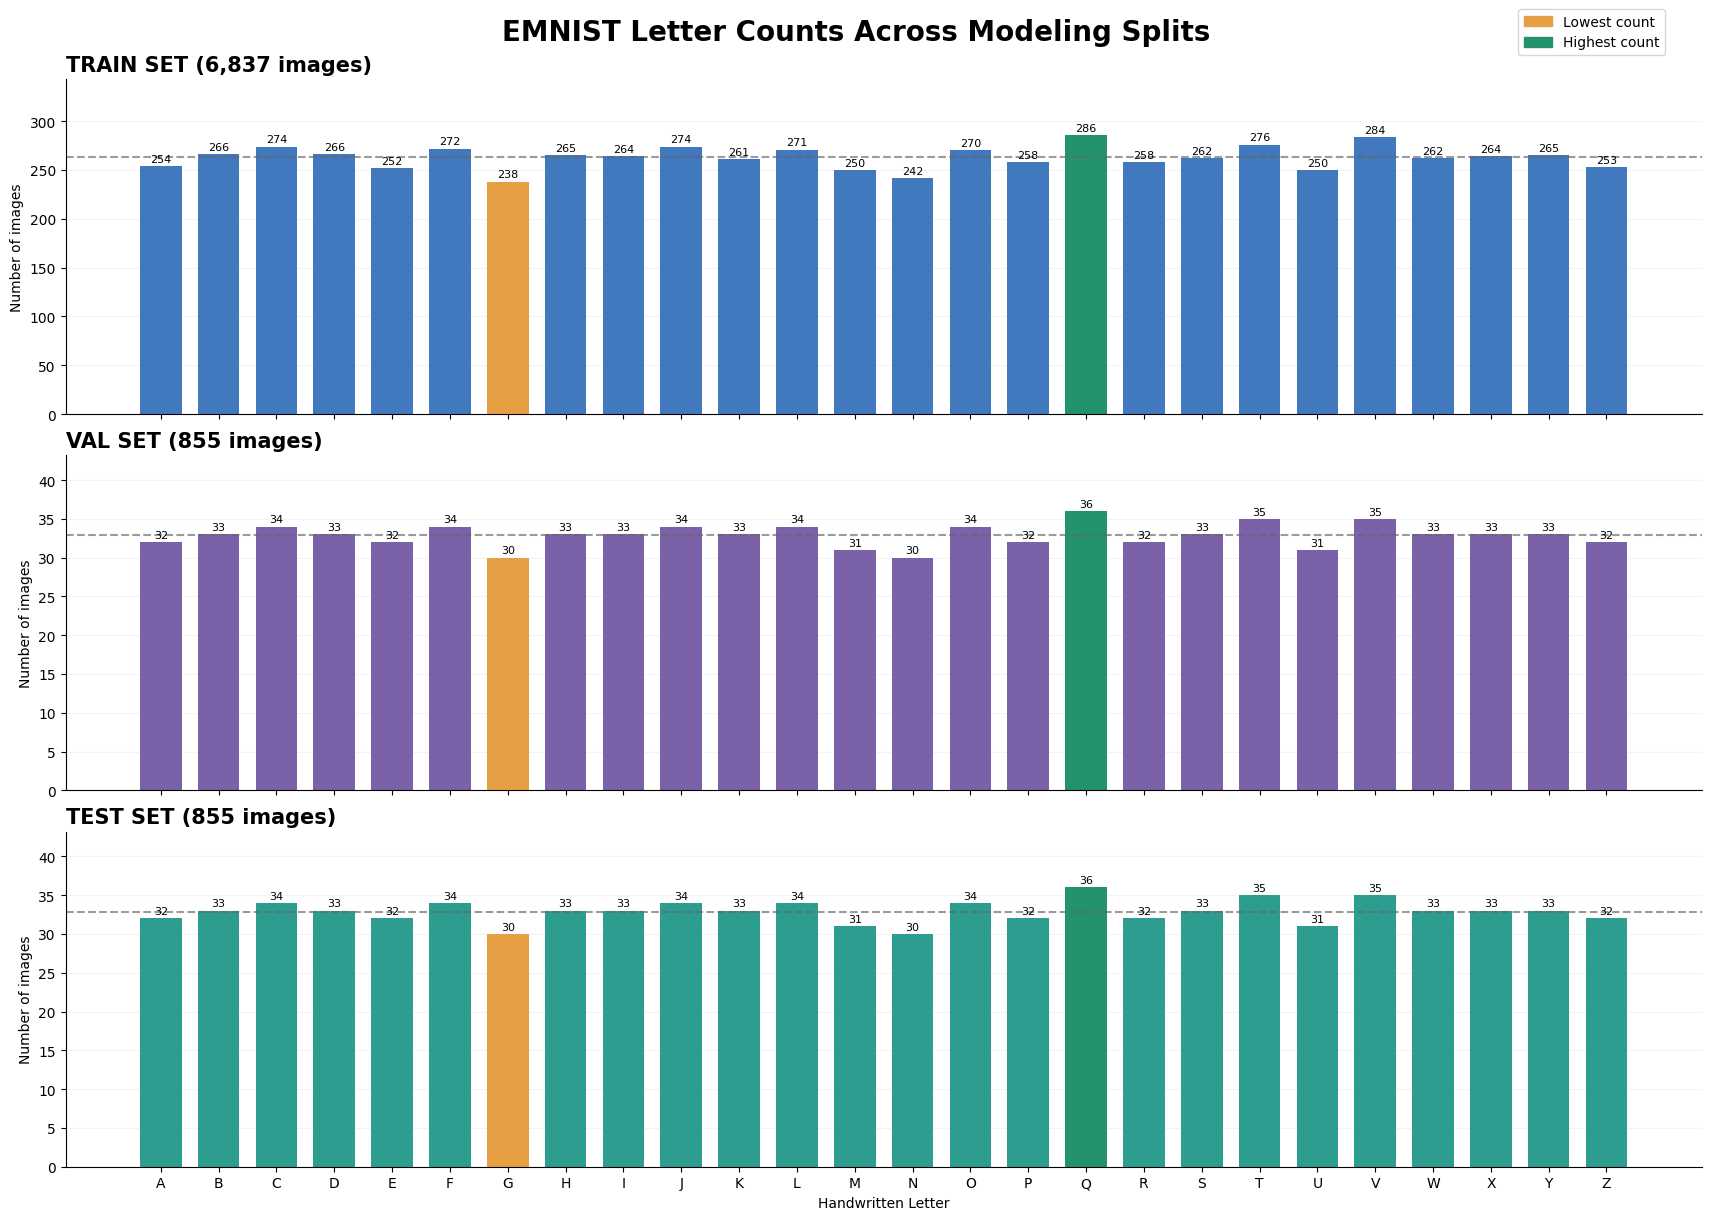

In [33]:
###  Three-panel bar chart showing actual letter counts

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

fig, axes = plt.subplots(
    3, 1,
    figsize=(17, 12),
    sharex=True,
    constrained_layout=True
)

colors_by_split = {
    "train": "#4178BE",
    "val": "#7B61A8",
    "test": "#2D9D8F"
}

x = np.arange(26)

for ax, split in zip(
    axes, ["train", "val", "test"]
):

    counts = counts_df[split].to_numpy()

    bar_colors = [colors_by_split[split]] * 26

    # Highlight lowest and highest count
    bar_colors[np.argmin(counts)] = "#E69F43"
    bar_colors[np.argmax(counts)] = "#23936B"

    bars = ax.bar(
        x,
        counts,
        color=bar_colors,
        width=0.72
    )

    # Show the actual count above every letter
    for bar, count in zip(bars, counts):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + counts.max() * 0.015,
            str(int(count)),
            ha="center",
            fontsize=8
        )

    ax.axhline(
        counts.mean(),
        color="#666666",
        linestyle="--",
        alpha=0.65
    )

    ax.set_ylim(0, counts.max() * 1.20)
    ax.set_ylabel("Number of images")

    ax.set_title(
        f"{split.upper()} SET "
        f"({counts.sum():,} images)",
        fontsize=15,
        fontweight="bold",
        loc="left"
    )

    ax.grid(axis="y", alpha=0.15)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[-1].set_xticks(x)
axes[-1].set_xticklabels(LETTERS, fontsize=10)
axes[-1].set_xlabel("Handwritten Letter")

fig.legend(
    handles=[
        Patch(color="#E69F43", label="Lowest count"),
        Patch(color="#23936B", label="Highest count")
    ],
    loc="upper right",
    bbox_to_anchor=(0.98, 1.01)
)

fig.suptitle(
    "EMNIST Letter Counts Across Modeling Splits",
    fontsize=20,
    fontweight="bold"
)

fig.savefig(
    FIGURE_DIR / "letter_counts_by_split.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()



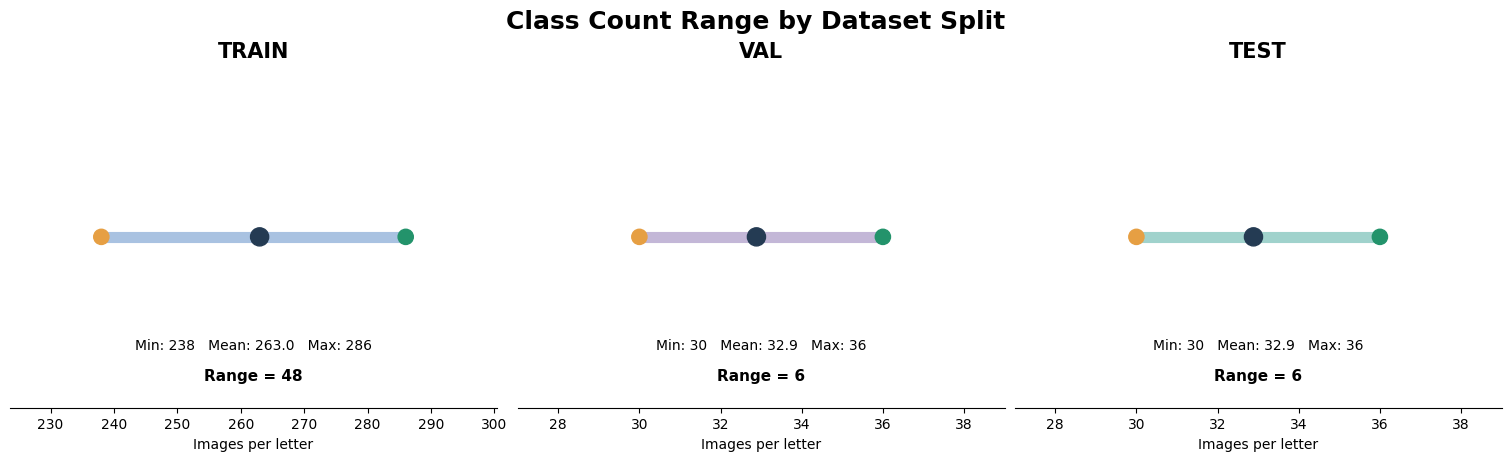

In [34]:
### Visualize the range in each dataset split


# MINIMUM - MEAN - MAXIMUM RANGE CHART

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4.5),
    constrained_layout=True
)

split_colors = {
    "train": "#4178BE",
    "val": "#7B61A8",
    "test": "#2D9D8F"
}

for ax, split in zip(
    axes, ["train", "val", "test"]
):

    values = counts_df[split].to_numpy()

    mn = int(values.min())
    mx = int(values.max())
    avg = float(values.mean())

    # Range line
    ax.plot(
        [mn, mx], [0, 0],
        color=split_colors[split],
        linewidth=8,
        alpha=0.45,
        solid_capstyle="round"
    )

    # Lowest, mean and highest
    ax.scatter(
        [mn, avg, mx],
        [0, 0, 0],
        s=[120, 170, 120],
        color=[
            "#E69F43",
            "#243B53",
            "#23936B"
        ],
        zorder=5
    )

    padding = max((mx - mn) * 0.30, 3)
    ax.set_xlim(mn - padding, mx + padding)
    ax.set_ylim(-0.8, 0.8)

    ax.set_yticks([])
    ax.set_xlabel("Images per letter")

    ax.set_title(
        split.upper(),
        fontsize=15,
        fontweight="bold"
    )

    ax.text(
        0.5, 0.17,
        f"Min: {mn}   Mean: {avg:.1f}   Max: {mx}",
        transform=ax.transAxes,
        ha="center",
        fontsize=10
    )

    ax.text(
        0.5, 0.08,
        f"Range = {mx - mn}",
        transform=ax.transAxes,
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

    ax.spines[["top", "right", "left"]].set_visible(False)

fig.suptitle(
    "Class Count Range by Dataset Split",
    fontsize=18,
    fontweight="bold"
)

fig.savefig(
    FIGURE_DIR / "class_count_ranges.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()


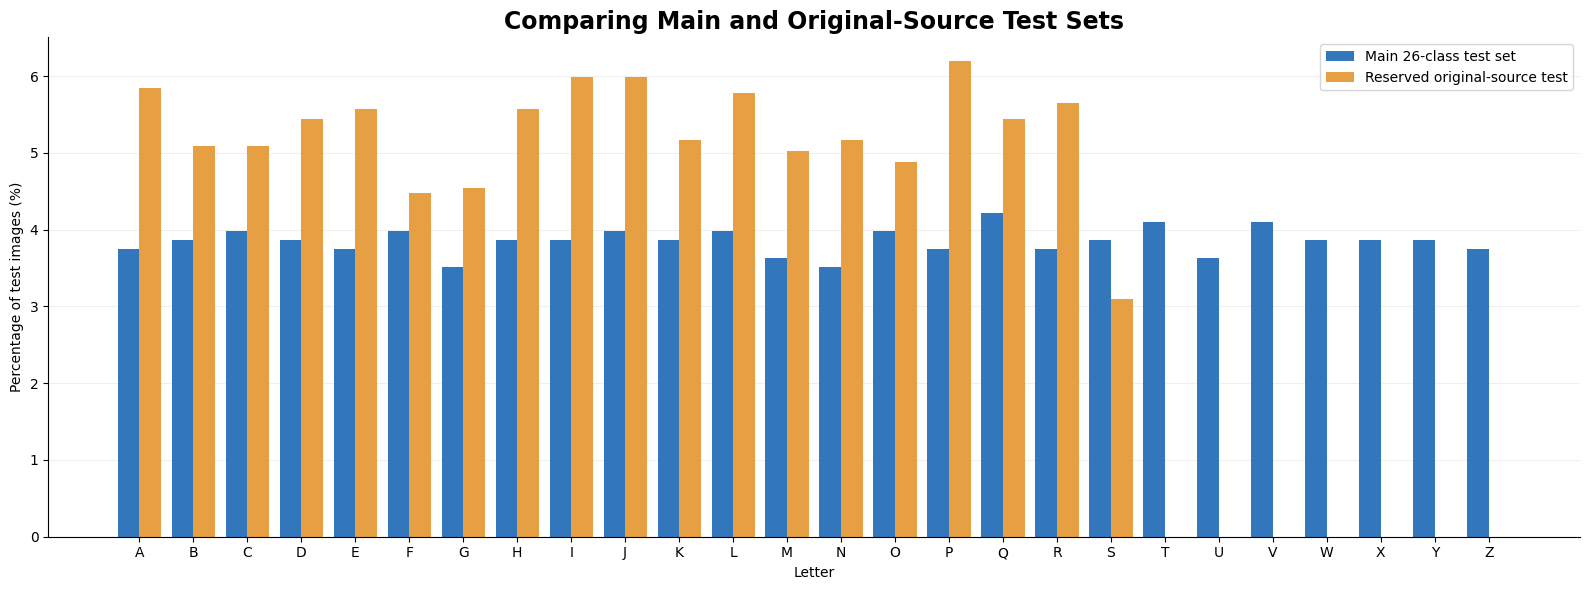

MAIN TEST SET
Images: 855
Classes: 26

RESERVED SOURCE TEST
Images: 1453
Classes: 19
Missing letters: ['T', 'U', 'V', 'W', 'X', 'Y', 'Z']


In [35]:
### Comparing the main test set with the reserved original test set

import numpy as np
import matplotlib.pyplot as plt

reserved_path = DATA_DIR / "original_test_optional.npz"

if not reserved_path.is_file():
    print("Reserved source-test file not found.")

else:
    with np.load(reserved_path, allow_pickle=False) as data:
        original_y = data["y"].astype(int)

    original_counts = np.bincount(
        original_y, minlength=26
    )

    main_counts = counts_df["test"].to_numpy()

    original_percent = (
        100 * original_counts / original_counts.sum()
    )

    main_percent = (
        100 * main_counts / main_counts.sum()
    )

    x = np.arange(26)
    width = 0.40

    fig, ax = plt.subplots(figsize=(16, 6))

    ax.bar(
        x - width / 2,
        main_percent,
        width,
        label="Main 26-class test set",
        color="#3276BC"
    )

    ax.bar(
        x + width / 2,
        original_percent,
        width,
        label="Reserved original-source test",
        color="#E69F43"
    )

    ax.set_xticks(x)
    ax.set_xticklabels(LETTERS)

    ax.set_xlabel("Letter")
    ax.set_ylabel("Percentage of test images (%)")

    ax.set_title(
        "Comparing Main and Original-Source Test Sets",
        fontsize=17,
        fontweight="bold"
    )

    ax.legend()
    ax.grid(axis="y", alpha=0.20)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()

    fig.savefig(
        FIGURE_DIR / "test_set_comparison.png",
        dpi=250,
        bbox_inches="tight"
    )

    plt.show()

    missing = [
        LETTERS[i]
        for i in range(26)
        if original_counts[i] == 0
    ]

    print("MAIN TEST SET")
    print("Images:", main_counts.sum())
    print("Classes:", np.count_nonzero(main_counts))

    print("\nRESERVED SOURCE TEST")
    print("Images:", original_counts.sum())
    print("Classes:", np.count_nonzero(original_counts))
    print("Missing letters:", missing)
